In [1310]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [1311]:
df = pd.read_csv(r"D:\pycharm\Pipelined\data\house_prices\train.csv")
df_test = pd.read_csv(r"D:\pycharm\Pipelined\data\house_prices\test.csv")

In [1312]:
df.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [1313]:
df.duplicated().sum()

np.int64(0)

In [1314]:
df_test.duplicated().sum()

np.int64(0)

In [1315]:
df_test.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           4
LotFrontage      227
LotArea            0
                ... 
MiscVal            0
MoSold             0
YrSold             0
SaleType           1
SaleCondition      0
Length: 80, dtype: int64

In [1316]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



# Первый взгялд на данные и разбор колонок

Из файла с описанием данных сразу видно некоторые моменты

MSSubClass - очень странный признак, OHE

MSZoning - Это надо будет кодировать, вероятнее всего Target Encoding'ом, так как цена будет отличаться на разные зоны

LotFrontage - явная заисимость от LotArea и LotShape, LotConfig

Street - Тут OHE

Alley - Также OHE, можно выделить признак, что нет дорожки

LotShape - Выглядит как будто можно сделать ординальным признаком

LandContour - Ординальный признак

Utilities - Определенно точно ординальный признак, важный, но надо бы посмотреть распределение, думаю, что большинство домов будет AllPub, поэтому лучше просто будет выделить Allpub или нет

LotConfig - тяжело сказать сразу, вероятнее всего OHE

LandSlope - Ординальный

Neighborhood - Очень важный признак, либо таргер, либо каунт кодирование

Condition1/2 - Думаю что необходимо объединение и важно посмотреть их вместе

BldgType - OHE/посмотреть распределение

HouseStyle - OHE

OverallQual - Тоже очень важный признак, не трогать

OverallCond - также

YearBuilt - оставить

YearRemodAdd - будто бы можно выделить признак была ли реновация, надо изучить


RoofStyle - OHE/drop

RoofMatl - OHE

Exterior1st - OHE

Exterior2nd - OHE

MasVnrType - OHE

ExterQual - ординальный

ExterCond - ординальный

Foundation - будто бы тоже ордианльный, материал важен, но тяжело сказать какой лучший, возможно таргетом надо кодировать

BsmtQual - Ординальный

BsmtCond - Ординальный

BsmtExposure - Ординальный

BsmtFinType1 - Ординальный

BsmtFinType2 - Ординальный



Heating - OHE

HeatingQC - Ординальный

CentralAir - OHE

Electrical - подозреваю, что ординальный, но может быть и OHE/target

LowQualFinSF - важный признак на первый взгляд, большинство значений будут 0, соответсвенно можно сделать признак >0

KitchenQual - Ординальный

Functional - Такеж ординальный

FireplaceQu - Ординальный

GarageType - OHE/target

GarageFinish - Ординальный

GarageCars - Довольно интересный признак, надо обратить внимание, так как дома с гаражом на условные 5 машин, будут явно выше в цене

GarageQual - Ординальный

GarageCond - Ординальный

PavedDrive - Ординальный

PoolQC - также дома, у которых не NA будут явно выше в стоимости, ординальный признак

Fence - Ординальный

MiscFeature - дома с TenC будут явно дороже, в целом OHE

SaleType - OHE
SaleCondition - OHE

Итого: Очень много OHE признаков, очень разряженная матрица для линейных моделей, лучше использовать деревья, бустинги, также использование l1 чтобы выделить признаки


# Разбор каждого признака побробно



MSSubClass

In [1317]:
print(df['MSSubClass'].isnull().sum())
print(df['MSSubClass'].value_counts())
print(df['MSSubClass'].value_counts().sort_index())


0
MSSubClass
20     536
60     299
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      20
75      16
45      12
180     10
40       4
Name: count, dtype: int64
MSSubClass
20     536
30      69
40       4
45      12
50     144
60     299
70      60
75      16
80      58
85      20
90      52
120     87
160     63
180     10
190     30
Name: count, dtype: int64


In [1318]:
print(df_test['MSSubClass'].isnull().sum())
print(df_test['MSSubClass'].value_counts())
print(df_test['MSSubClass'].value_counts().sort_index())

0
MSSubClass
20     543
60     276
50     143
120     95
30      70
70      68
160     65
80      60
90      57
190     31
85      28
75       7
180      7
45       6
40       2
150      1
Name: count, dtype: int64
MSSubClass
20     543
30      70
40       2
45       6
50     143
60     276
70      68
75       7
80      60
85      28
90      57
120     95
150      1
160     65
180      7
190     31
Name: count, dtype: int64


In [1319]:
import pandas as pd

def process_mssubclass(df):
    df = df.copy()
    df['MSSubClass'] = df['MSSubClass'].astype(str)
    return df

df = process_mssubclass(df)
df_test = process_mssubclass(df_test)

In [1320]:
print(df['MSZoning'].value_counts())
print(df['MSZoning'].isnull().sum())

MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64
0


так как всего 5 значений, лучше взять OHE, выглядит осмысленно и не сильно разряжает матрицу признаков

LotFrontage

In [1321]:
print(df['LotFrontage'].isnull().sum())
print(df_test['LotFrontage'].isnull().sum())

259
227


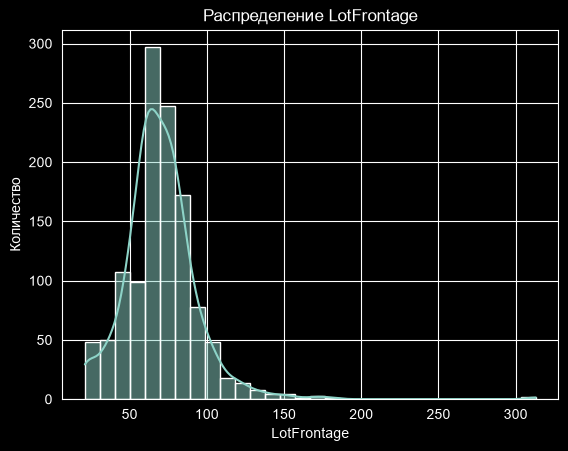

In [1322]:
plt.figure()
sns.histplot(df['LotFrontage'], kde=True, bins=30)
plt.title('Распределение LotFrontage')
plt.xlabel('LotFrontage')
plt.ylabel('Количество')
plt.show()

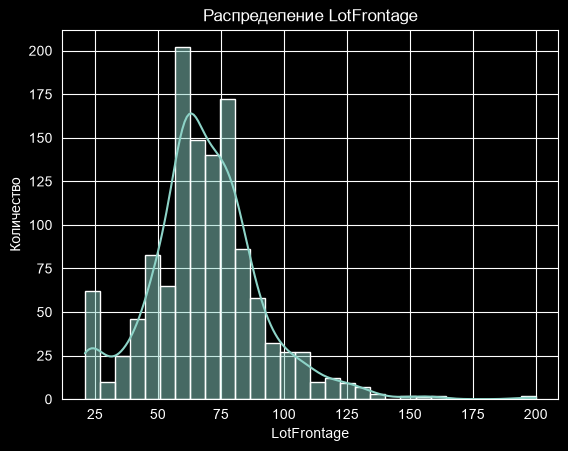

In [1323]:
plt.figure()
sns.histplot(df_test['LotFrontage'], kde=True, bins=30)
plt.title('Распределение LotFrontage')
plt.xlabel('LotFrontage')
plt.ylabel('Количество')
plt.show()

In [1324]:
upper_limit = 200

df['LotFrontage'] = df['LotFrontage'].clip(upper=upper_limit)
df_test['LotFrontage'] = df_test['LotFrontage'].clip(upper=upper_limit)

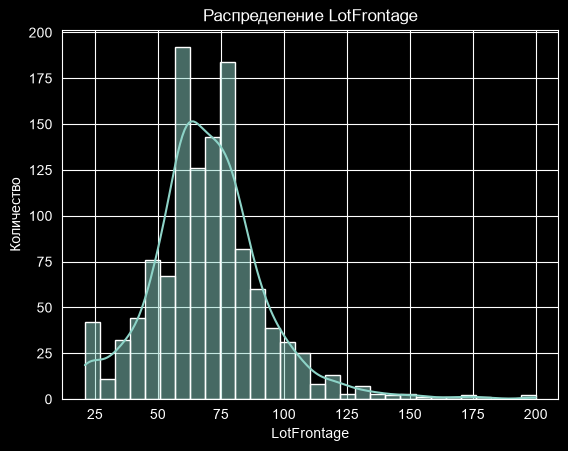

In [1325]:
plt.figure()
sns.histplot(df['LotFrontage'], kde=True, bins=30)
plt.title('Распределение LotFrontage')
plt.xlabel('LotFrontage')
plt.ylabel('Количество')
plt.show()

In [1326]:
med_l1 = df.groupby(['Neighborhood', 'LotConfig'])['LotFrontage'].median()
med_l2 = df.groupby('Neighborhood')['LotFrontage'].median()
med_global = df['LotFrontage'].median()

l1_train = pd.Series(df.set_index(['Neighborhood', 'LotConfig']).index.map(med_l1), index=df.index)
l2_train = df['Neighborhood'].map(med_l2)
df['LotFrontage'] = df['LotFrontage'].fillna(l1_train).fillna(l2_train).fillna(med_global)

l1_test = pd.Series(df_test.set_index(['Neighborhood', 'LotConfig']).index.map(med_l1), index=df_test.index)
l2_test = df_test['Neighborhood'].map(med_l2)
df_test['LotFrontage'] = df_test['LotFrontage'].fillna(l1_test).fillna(l2_test).fillna(med_global)

In [1327]:
print(df['LotFrontage'].isnull().sum())
print(df_test['LotFrontage'].isnull().sum())

0
0


LotArea

In [1328]:
print(df['LotArea'].isnull().sum())
print(df_test['LotArea'].isnull().sum())

0
0


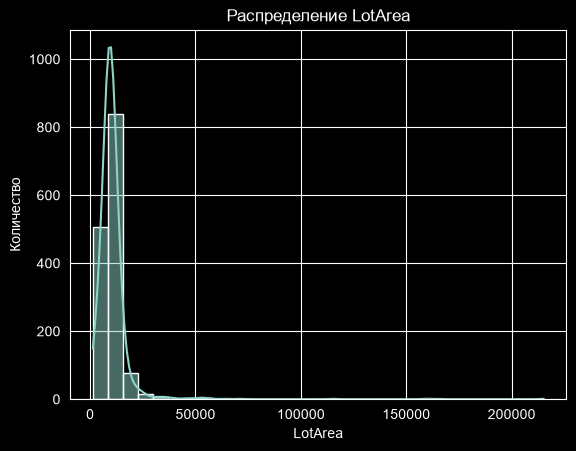

In [1329]:
plt.figure()
sns.histplot(df['LotArea'], kde=True, bins=30)
plt.title('Распределение LotArea')
plt.xlabel('LotArea')
plt.ylabel('Количество')
plt.show()

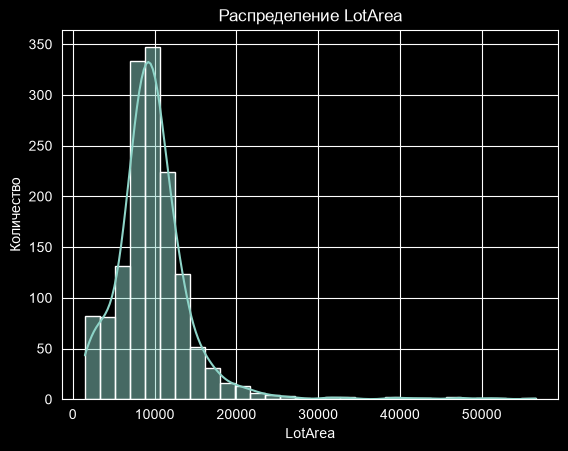

In [1330]:
plt.figure()
sns.histplot(df_test['LotArea'], kde=True, bins=30)
plt.title('Распределение LotArea')
plt.xlabel('LotArea')
plt.ylabel('Количество')
plt.show()

In [1331]:
df['LotArea'] = np.log1p(df['LotArea'])
df_test['LotArea'] = np.log1p(df_test['LotArea'])

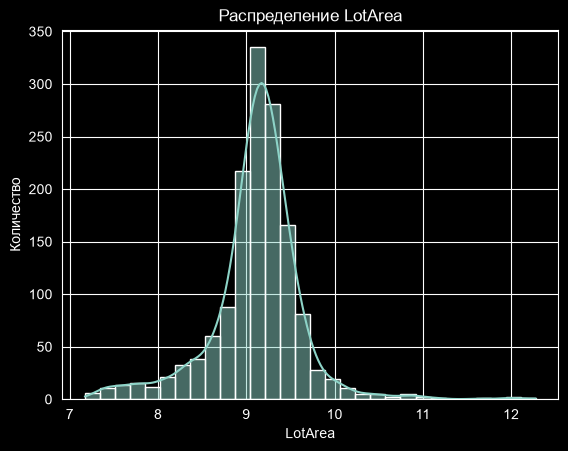

In [1332]:
plt.figure()
sns.histplot(df['LotArea'], kde=True, bins=30)
plt.title('Распределение LotArea')
plt.xlabel('LotArea')
plt.ylabel('Количество')
plt.show()

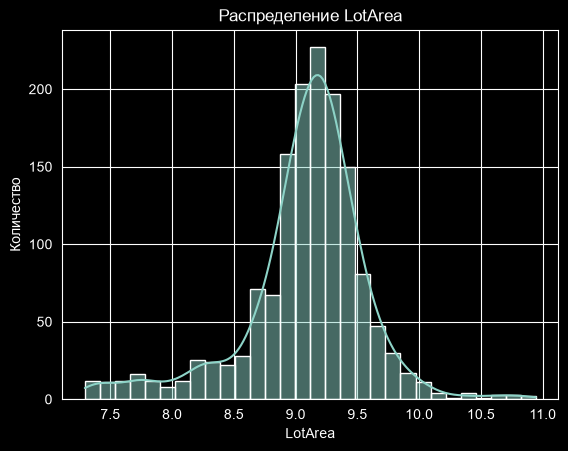

In [1333]:
plt.figure()
sns.histplot(df_test['LotArea'], kde=True, bins=30)
plt.title('Распределение LotArea')
plt.xlabel('LotArea')
plt.ylabel('Количество')
plt.show()

Street

In [1334]:
print(df['Street'].isnull().sum())
print(df_test['Street'].isnull().sum())

0
0


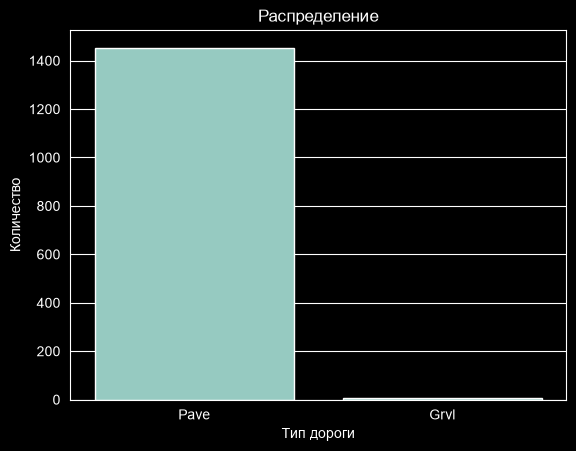

In [1335]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure()
sns.countplot(data=df, x='Street')
plt.title('Распределение')
plt.xlabel('Тип дороги')
plt.ylabel('Количество')
plt.show()

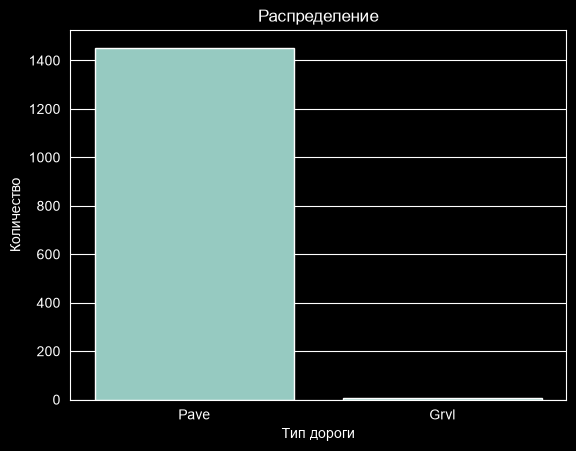

In [1336]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure()
sns.countplot(data=df_test, x='Street')
plt.title('Распределение')
plt.xlabel('Тип дороги')
plt.ylabel('Количество')
plt.show()

In [1337]:
print(df['Street'].value_counts(dropna=False))
print(df_test['Street'].value_counts(dropna=False))

Street
Pave    1454
Grvl       6
Name: count, dtype: int64
Street
Pave    1453
Grvl       6
Name: count, dtype: int64


признак лучше всего просто дропнуть

In [1338]:
df = df.drop(columns=['Street'])
df_test = df_test.drop(columns=['Street'])

Alley

In [1339]:
print(df['Alley'].isnull().sum())
print(df_test['Alley'].isnull().sum())

1369
1352


In [1340]:
df['Alley'] = df['Alley'].fillna("None")
df_test['Alley'] = df_test['Alley'].fillna("None")

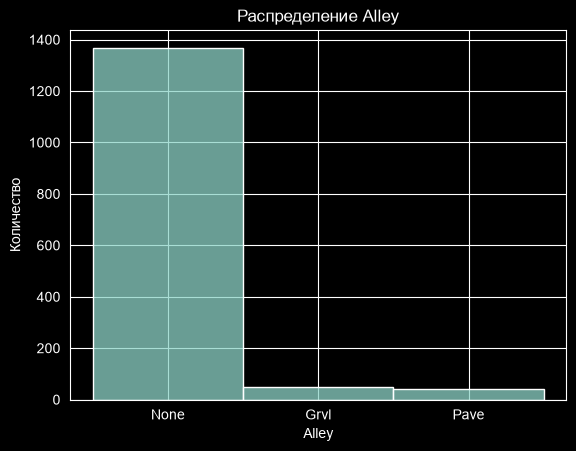

In [1341]:
plt.figure()
sns.histplot(df['Alley'], kde=False, bins=30)
plt.title('Распределение Alley')
plt.xlabel('Alley')
plt.ylabel('Количество')
plt.show()

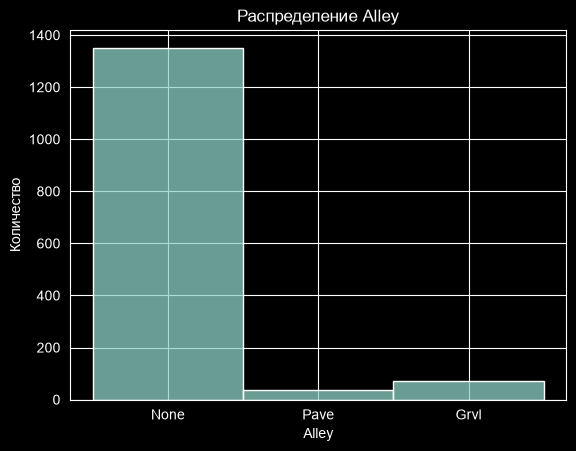

In [1342]:
plt.figure()
sns.histplot(df_test['Alley'], kde=False, bins=30)
plt.title('Распределение Alley')
plt.xlabel('Alley')
plt.ylabel('Количество')
plt.show()

LotShape


In [1343]:
print(df['LotShape'].isnull().sum())
print(df_test['LotShape'].isnull().sum())

0
0


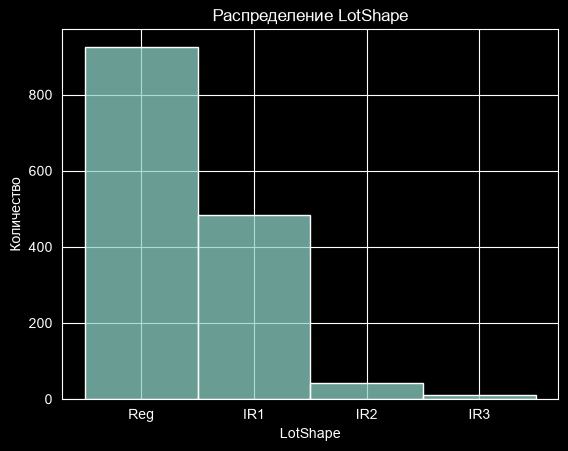

In [1344]:
plt.figure()
sns.histplot(df['LotShape'], kde=False, bins=30)
plt.title('Распределение LotShape')
plt.xlabel('LotShape')
plt.ylabel('Количество')
plt.show()

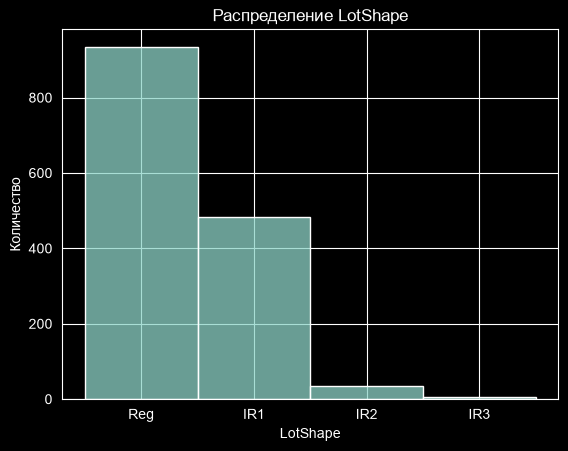

In [1345]:
plt.figure()
sns.histplot(df_test['LotShape'], kde=False, bins=30)
plt.title('Распределение LotShape')
plt.xlabel('LotShape')
plt.ylabel('Количество')
plt.show()

In [1346]:
df['Is_Regular_Lot'] = (df['LotShape'] == 'Reg').astype(int)
df_test['Is_Regular_Lot'] = (df_test['LotShape'] == 'Reg').astype(int)

LandContour

In [1347]:
print(df['LandContour'].isnull().sum())
print(df_test['LandContour'].isnull().sum())

0
0


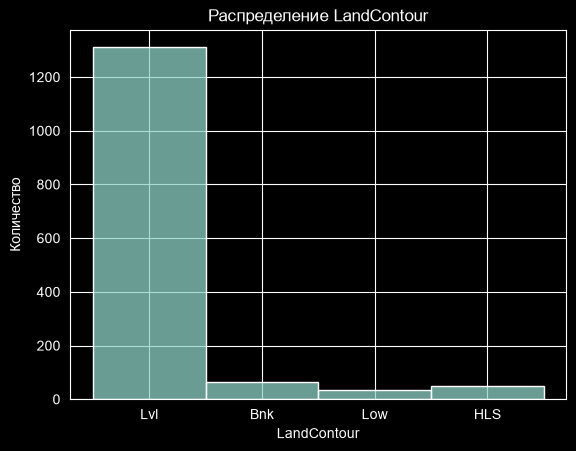

In [1348]:
plt.figure()
sns.histplot(df['LandContour'], kde=False, bins=30)
plt.title('Распределение LandContour')
plt.xlabel('LandContour')
plt.ylabel('Количество')
plt.show()

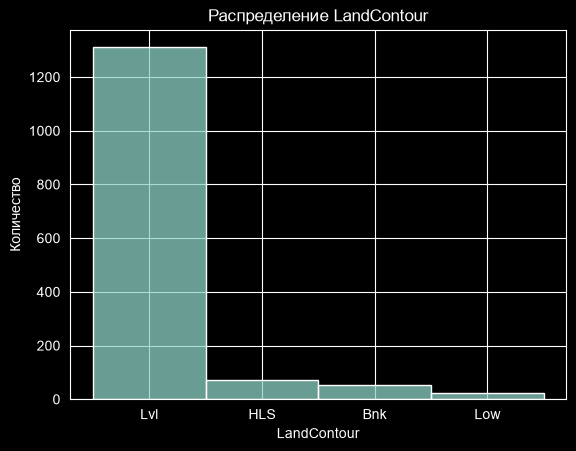

In [1349]:
plt.figure()
sns.histplot(df_test['LandContour'], kde=False, bins=30)
plt.title('Распределение LandContour')
plt.xlabel('LandContour')
plt.ylabel('Количество')
plt.show()

In [1350]:
df['Is_Level_Land'] = (df['LandContour'] == 'Lvl').astype(int)
df_test['Is_Level_Land'] = (df_test['LandContour'] == 'Lvl').astype(int)

Utilities

In [1351]:
print(df['Utilities'].isnull().sum())
print(df_test['Utilities'].isnull().sum())

0
2


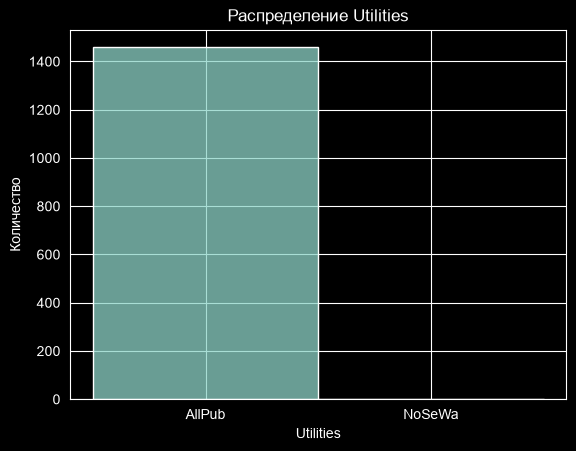

In [1352]:
plt.figure()
sns.histplot(df['Utilities'], kde=False, bins=30)
plt.title('Распределение Utilities')
plt.xlabel('Utilities')
plt.ylabel('Количество')
plt.show()

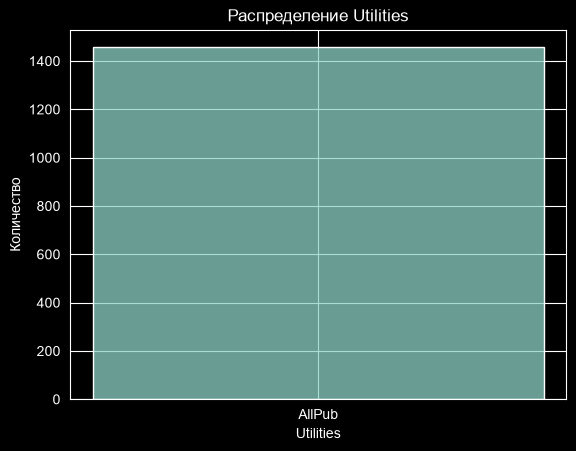

In [1353]:
plt.figure()
sns.histplot(df_test['Utilities'], kde=False, bins=30)
plt.title('Распределение Utilities')
plt.xlabel('Utilities')
plt.ylabel('Количество')
plt.show()

In [1354]:
df_test['Utilities'].describe()

count       1457
unique         1
top       AllPub
freq        1457
Name: Utilities, dtype: object

In [1355]:
df = df.drop(columns=['Utilities'])
df_test = df_test.drop(columns=['Utilities'])

LotConfig

In [1356]:
print(df['LotConfig'].isnull().sum())
print(df_test['LotConfig'].isnull().sum())

0
0


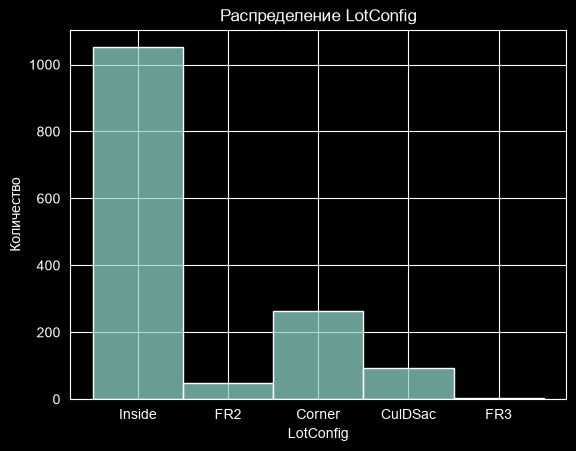

In [1357]:
plt.figure()
sns.histplot(df['LotConfig'], kde=False, bins=30)
plt.title('Распределение LotConfig')
plt.xlabel('LotConfig')
plt.ylabel('Количество')
plt.show()

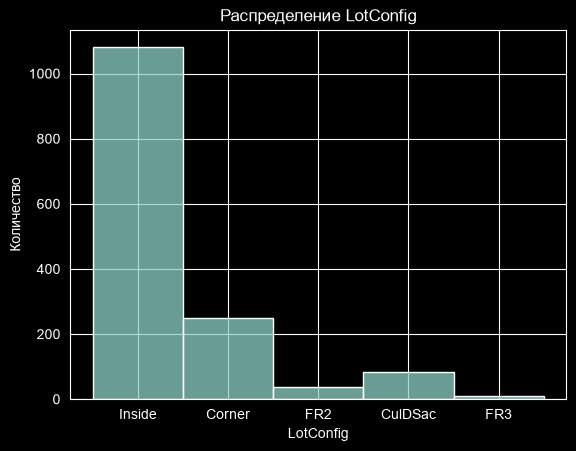

In [1358]:
plt.figure()
sns.histplot(df_test['LotConfig'], kde=False, bins=30)
plt.title('Распределение LotConfig')
plt.xlabel('LotConfig')
plt.ylabel('Количество')
plt.show()

In [1359]:
df['LotConfig'].value_counts()

LotConfig
Inside     1052
Corner      263
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64

In [1360]:
df_test['LotConfig'].value_counts()

LotConfig
Inside     1081
Corner      248
CulDSac      82
FR2          38
FR3          10
Name: count, dtype: int64

In [1361]:
df['LotConfig'] = df['LotConfig'].replace({'FR2': 'FR', 'FR3': 'FR'})
df_test['LotConfig'] = df_test['LotConfig'].replace({'FR2': 'FR', 'FR3': 'FR'})

LandSlope

In [1362]:
print(df['LandSlope'].isnull().sum())
print(df_test['LandSlope'].isnull().sum())

0
0


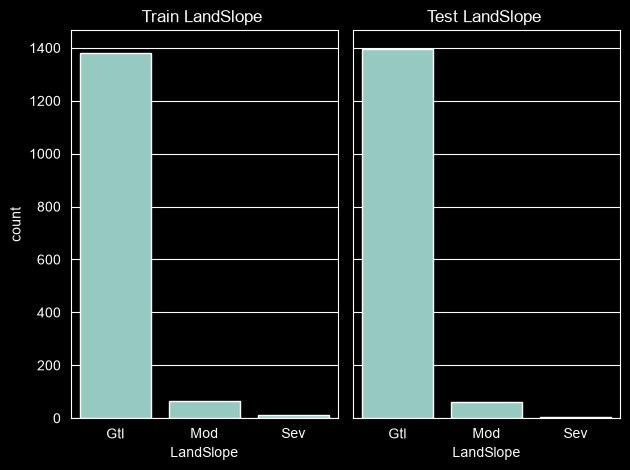

In [1363]:
fig, axes = plt.subplots(1, 2, sharey=True)

sns.countplot(data=df, x='LandSlope', ax=axes[0])
axes[0].set_title('Train LandSlope ')

sns.countplot(data=df_test, x='LandSlope', ax=axes[1])
axes[1].set_title('Test LandSlope ')

plt.tight_layout()
plt.show()

Neighborhood

In [1364]:
print(df['Neighborhood'].isnull().sum())
print(df_test['Neighborhood'].isnull().sum())

0
0


C:\Users\wany0\AppData\Local\Temp\ipykernel_6612\2533215671.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
C:\Users\wany0\AppData\Local\Temp\ipykernel_6612\2533215671.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')


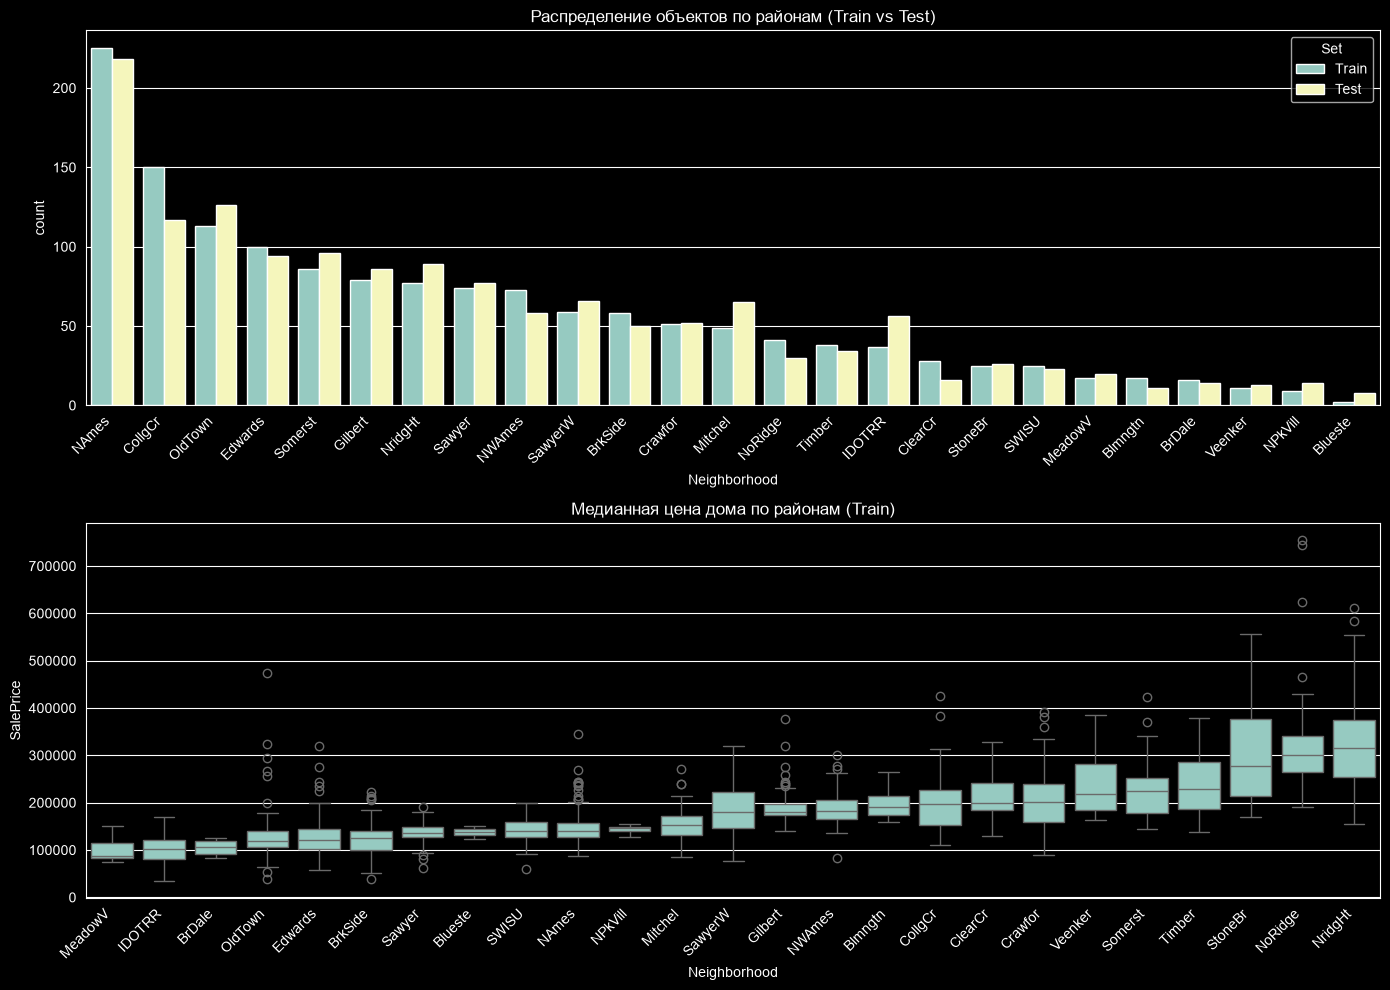

In [1365]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

combined = pd.concat([
    df[['Neighborhood']].assign(Set='Train'),
    df_test[['Neighborhood']].assign(Set='Test')
])
sns.countplot(data=combined, x='Neighborhood', hue='Set', ax=axes[0], order=df['Neighborhood'].value_counts().index)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].set_title('Распределение объектов по районам (Train vs Test)')

order = df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(data=df, x='Neighborhood', y='SalePrice', ax=axes[1], order=order)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].set_title('Медианная цена дома по районам (Train)')

plt.tight_layout()
plt.show()

Condition1

In [1366]:
print(df['Condition1'].isnull().sum())
print(df_test['Condition1'].isnull().sum())

0
0


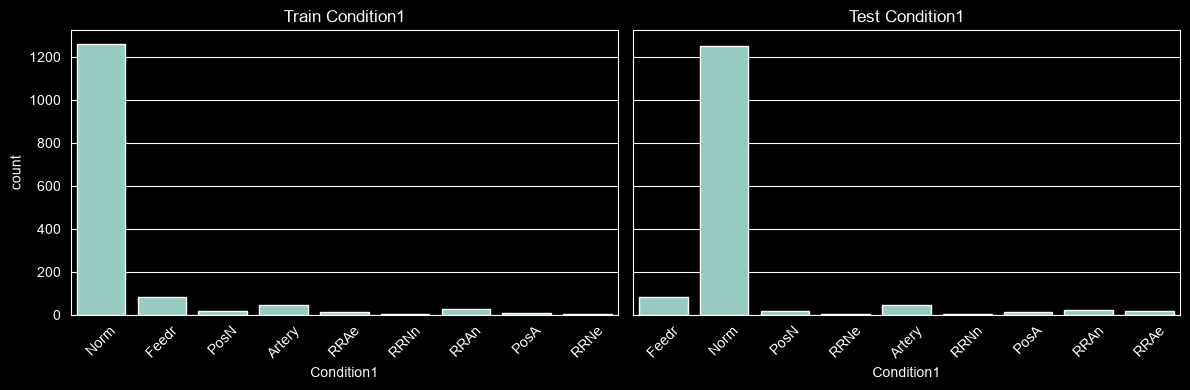

In [1367]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Condition1', ax=axes[0])
axes[0].set_title('Train Condition1')

sns.countplot(data=df_test, x='Condition1', ax=axes[1])
axes[1].set_title('Test Condition1')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Condition2

In [1368]:
print(df['Condition2'].isnull().sum())
print(df_test['Condition2'].isnull().sum())

0
0


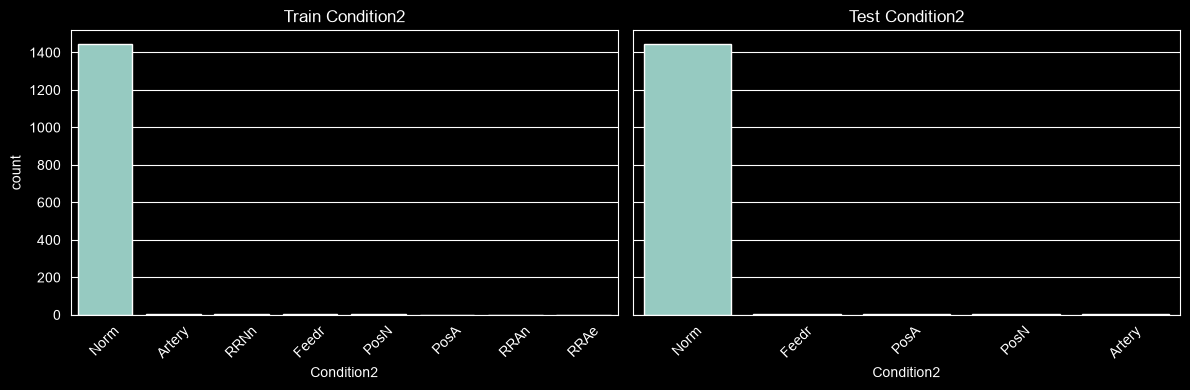

In [1369]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Condition2', ax=axes[0])
axes[0].set_title('Train Condition2')

sns.countplot(data=df_test, x='Condition2', ax=axes[1])
axes[1].set_title('Test Condition2')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1370]:
railroad = ['RRNn','RRAn','RRNe','RRAe']
street = ['Artery', 'Feedr']
park = ['PosN','PosA']

df['RailRoad'] = (df['Condition1'].isin(railroad) | df['Condition2'].isin(railroad)).astype(int)
df_test['RailRoad'] = (df_test['Condition1'].isin(railroad) | df_test['Condition2'].isin(railroad)).astype(int)

df['NearStreet']= (df['Condition1'].isin(street) | df['Condition2'].isin(street)).astype(int)
df_test['NearStreet'] = (df_test['Condition1'].isin(street) | df_test['Condition2'].isin(street)).astype(int)

df['NearPark']= (df['Condition1'].isin(park) | df['Condition2'].isin(park)).astype(int)
df_test['NearPark'] = (df_test['Condition1'].isin(park) | df_test['Condition2'].isin(park)).astype(int)

df = df.drop(columns=['Condition1','Condition2'])
df_test = df_test.drop(columns=['Condition1','Condition2'])



BldgType

In [1371]:
print(df['BldgType'].isnull().sum())
print(df_test['BldgType'].isnull().sum())

0
0


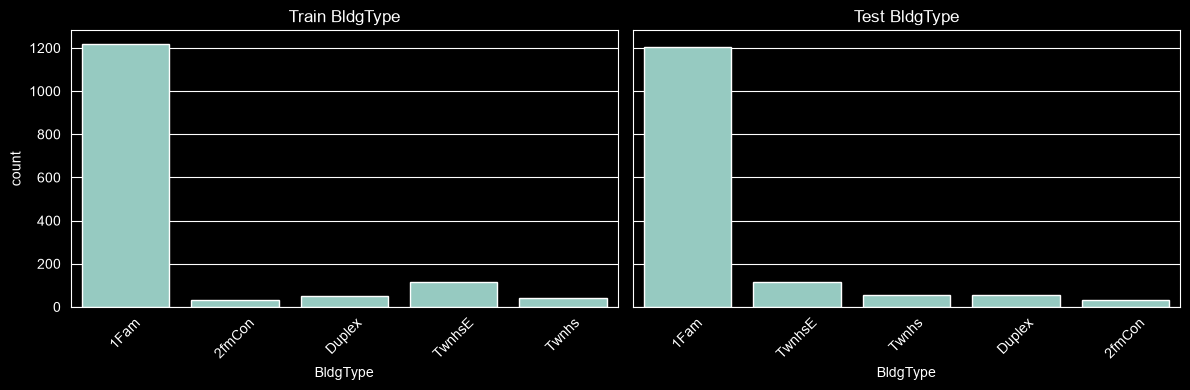

In [1372]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='BldgType', ax=axes[0])
axes[0].set_title('Train BldgType')

sns.countplot(data=df_test, x='BldgType', ax=axes[1])
axes[1].set_title('Test BldgType')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

HouseStyle

In [1373]:
print(df['HouseStyle'].isnull().sum())
print(df_test['HouseStyle'].isnull().sum())

0
0


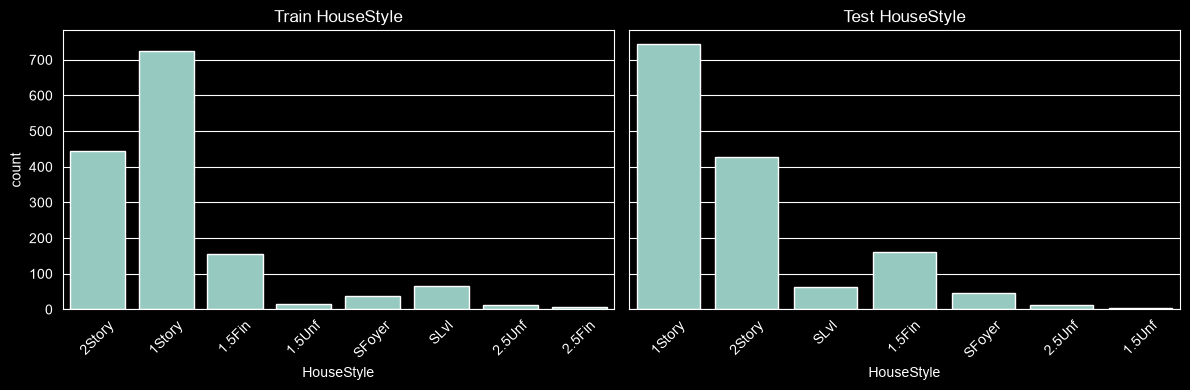

In [1374]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='HouseStyle', ax=axes[0])
axes[0].set_title('Train HouseStyle')

sns.countplot(data=df_test, x='HouseStyle', ax=axes[1])
axes[1].set_title('Test HouseStyle')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1375]:
style_map = {
    '1Story': '1Story',
    '1.5Fin': '1.5Story',
    '1.5Unf': '1.5Story',
    '2Story': '2Story',
    '2.5Fin': '2.5Story',
    '2.5Unf': '2.5Story',
    'SFoyer': 'Split',
    'SLvl': 'Split'
}

df['HouseStyle_Group'] = df['HouseStyle'].map(style_map)
df_test['HouseStyle_Group'] = df_test['HouseStyle'].map(style_map)
df = df.drop(columns=['HouseStyle'])
df_test = df_test.drop(columns=['HouseStyle'])

OverallQual

In [1376]:
print(df['OverallQual'].isnull().sum())
print(df_test['OverallQual'].isnull().sum())

0
0


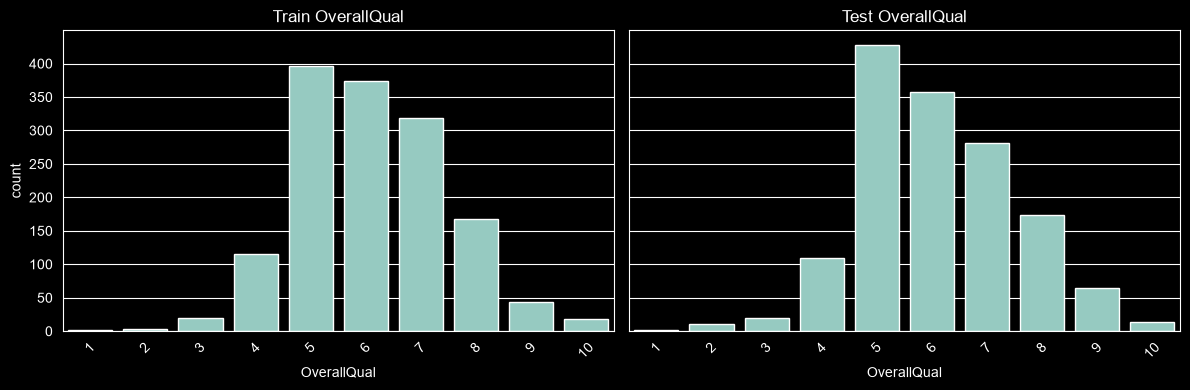

In [1377]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='OverallQual', ax=axes[0])
axes[0].set_title('Train OverallQual')

sns.countplot(data=df_test, x='OverallQual', ax=axes[1])
axes[1].set_title('Test OverallQual')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

OverallCond

In [1378]:
print(df['OverallCond'].isnull().sum())
print(df_test['OverallCond'].isnull().sum())

0
0


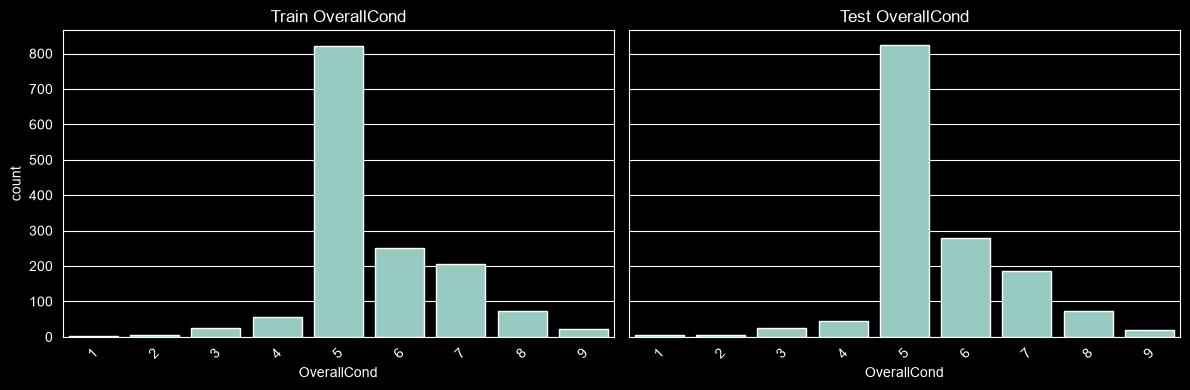

In [1379]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='OverallCond', ax=axes[0])
axes[0].set_title('Train OverallCond')

sns.countplot(data=df_test, x='OverallCond', ax=axes[1])
axes[1].set_title('Test OverallCond')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

YearBuilt + YearRemodAdd + YrSold

In [1380]:
print(df['YearBuilt'].isnull().sum())
print(df_test['YearBuilt'].isnull().sum())

0
0


In [1505]:
df['House_Age'] = np.maximum(0, df['YrSold'] - df['YearBuilt'])
df_test['House_Age'] = np.maximum(0, df_test['YrSold'] - df_test['YearBuilt'])

df['Remod_Age'] = np.maximum(0, df['YrSold'] - df['YearRemodAdd'])
df_test['Remod_Age'] = np.maximum(0, df_test['YrSold'] - df_test['YearRemodAdd'])

df['Is_Remodeled'] = (df['YearRemodAdd'] != df['YearBuilt']).astype(int)
df_test['Is_Remodeled'] = (df_test['YearRemodAdd'] != df_test['YearBuilt']).astype(int)

df['Age_At_Remod'] = df['YearRemodAdd'] - df['YearBuilt']
df_test['Age_At_Remod'] = df_test['YearRemodAdd'] - df_test['YearBuilt']

cols_to_drop = ['YearBuilt', 'YearRemodAdd']

df = df.drop(columns=cols_to_drop)
df_test = df_test.drop(columns=cols_to_drop)

YearRemodAdd

In [1382]:
print(df['YearRemodAdd'].isnull().sum())
print(df_test['YearRemodAdd'].isnull().sum())

0
0


RoofStyle

In [1383]:
print(df['RoofStyle'].isnull().sum())
print(df_test['RoofStyle'].isnull().sum())

0
0


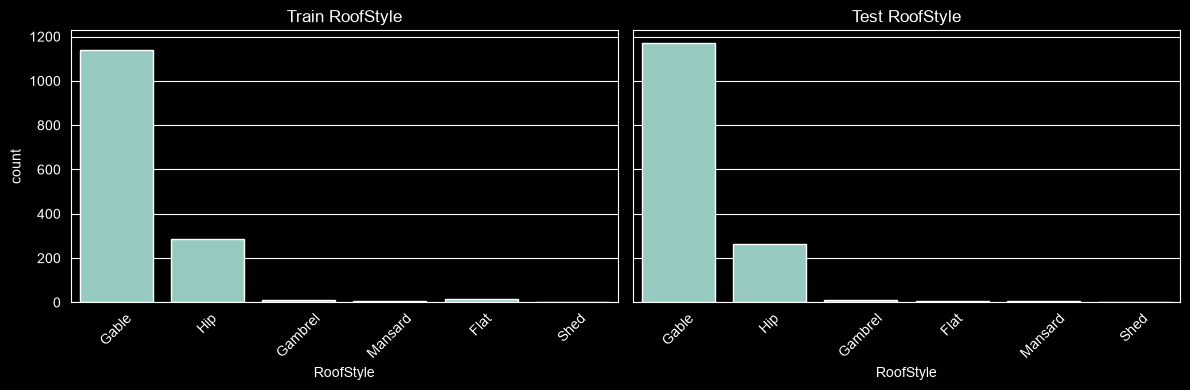

In [1384]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='RoofStyle', ax=axes[0])
axes[0].set_title('Train RoofStyle')

sns.countplot(data=df_test, x='RoofStyle', ax=axes[1])
axes[1].set_title('Test RoofStyle')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1385]:
roof_map = {
    'Gable': 'Gable',
    'Hip': 'Hip'
}

df['RoofStyle'] = df['RoofStyle'].map(roof_map).fillna('Other')
df_test['RoofStyle'] = df_test['RoofStyle'].map(roof_map).fillna('Other')

RoofMatl

In [1386]:
print(df['RoofMatl'].isnull().sum())
print(df_test['RoofMatl'].isnull().sum())

0
0


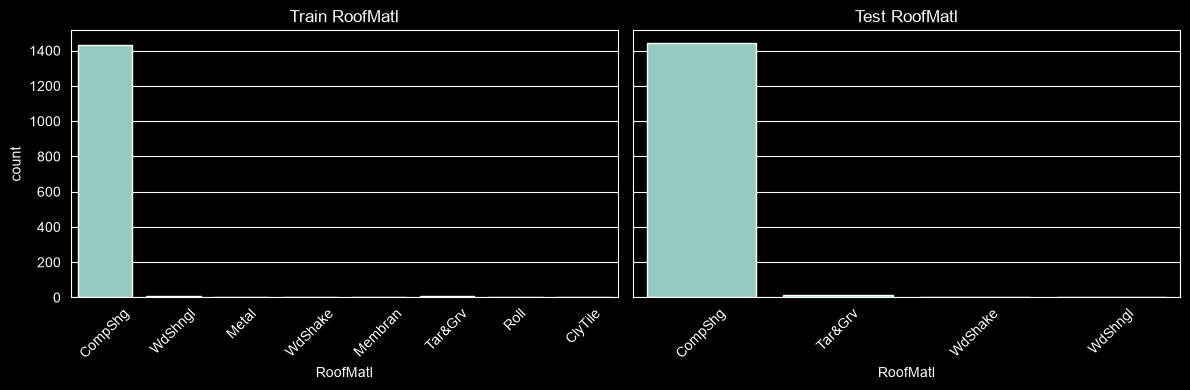

In [1387]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='RoofMatl', ax=axes[0])
axes[0].set_title('Train RoofMatl')

sns.countplot(data=df_test, x='RoofMatl', ax=axes[1])
axes[1].set_title('Test RoofMatl')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1388]:
df = df.drop(columns=['RoofMatl'])
df_test = df_test.drop(columns=['RoofMatl'])

Exterior1st

In [1389]:
print(df['Exterior1st'].isnull().sum())
print(df_test['Exterior1st'].isnull().sum())

0
1


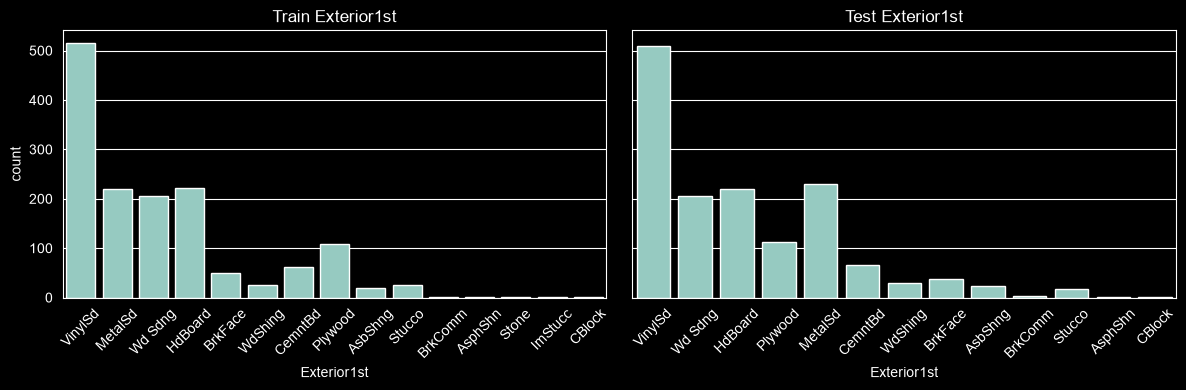

In [1390]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Exterior1st', ax=axes[0])
axes[0].set_title('Train Exterior1st')

sns.countplot(data=df_test, x='Exterior1st', ax=axes[1])
axes[1].set_title('Test Exterior1st')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Exterior2nd

In [1391]:
print(df['Exterior2nd'].isnull().sum())
print(df_test['Exterior2nd'].isnull().sum())

0
1


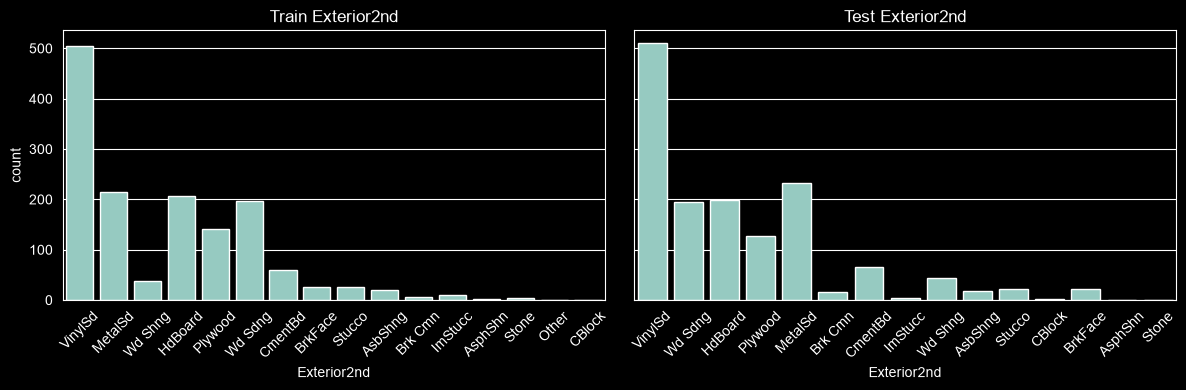

In [1392]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Exterior2nd', ax=axes[0])
axes[0].set_title('Train Exterior2nd')

sns.countplot(data=df_test, x='Exterior2nd', ax=axes[1])
axes[1].set_title('Test Exterior2nd')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1393]:
ext1_global_mode = df['Exterior1st'].mode()[0]
ext2_global_mode = df['Exterior2nd'].mode()[0]

ext1_neigh_mode = df.groupby('Neighborhood')['Exterior1st'].agg(
    lambda x: x.mode()[0] if not x.mode().empty else ext1_global_mode
)
ext2_neigh_mode = df.groupby('Neighborhood')['Exterior2nd'].agg(
    lambda x: x.mode()[0] if not x.mode().empty else ext2_global_mode
)

df_test['Exterior1st'] = df_test['Exterior1st'].fillna(df_test['Neighborhood'].map(ext1_neigh_mode)).fillna(ext1_global_mode)
df_test['Exterior2nd'] = df_test['Exterior2nd'].fillna(df_test['Neighborhood'].map(ext2_neigh_mode)).fillna(ext2_global_mode)

In [1394]:
df['Exterior1st'].unique()

<StringArray>
['VinylSd', 'MetalSd', 'Wd Sdng', 'HdBoard', 'BrkFace', 'WdShing', 'CemntBd',
 'Plywood', 'AsbShng',  'Stucco', 'BrkComm', 'AsphShn',   'Stone', 'ImStucc',
  'CBlock']
Length: 15, dtype: str

In [1395]:
df['Exterior2nd'].unique()

<StringArray>
['VinylSd', 'MetalSd', 'Wd Shng', 'HdBoard', 'Plywood', 'Wd Sdng', 'CmentBd',
 'BrkFace',  'Stucco', 'AsbShng', 'Brk Cmn', 'ImStucc', 'AsphShn',   'Stone',
   'Other',  'CBlock']
Length: 16, dtype: str

In [1396]:
typo_map = {
    'CmentBd': 'CemntBd',
    'Wd Shng': 'WdShing',
    'Brk Cmn': 'BrkComm'
}
df['Exterior2nd'] = df['Exterior2nd'].replace(typo_map)
df_test['Exterior2nd'] = df_test['Exterior2nd'].replace(typo_map)

top_materials = ['VinylSd', 'MetalSd', 'HdBoard', 'Wd Sdng', 'Plywood', 'CemntBd', 'WdShing']

df['Exterior1st'] = df['Exterior1st'].apply(lambda x: x if x in top_materials else 'Other')
df_test['Exterior1st'] = df_test['Exterior1st'].apply(lambda x: x if x in top_materials else 'Other')

df['Is_Multiple_Exterior'] = (df['Exterior1st'] != df['Exterior2nd']).astype(int)
df_test['Is_Multiple_Exterior'] = (df_test['Exterior1st'] != df_test['Exterior2nd']).astype(int)


df['Exterior2nd'] = df['Exterior2nd'].apply(lambda x: x if x in top_materials else 'Other')
df_test['Exterior2nd'] = df_test['Exterior2nd'].apply(lambda x: x if x in top_materials else 'Other')

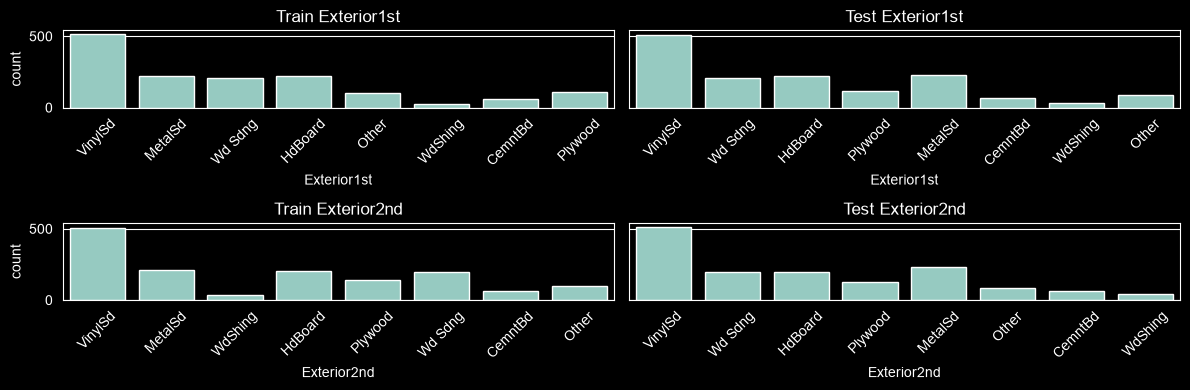

In [1397]:
fig, axes = plt.subplots(2, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Exterior1st', ax=axes[0,0])
axes[0,0].set_title('Train Exterior1st')
sns.countplot(data=df_test, x='Exterior1st', ax=axes[0,1])
axes[0,1].set_title('Test Exterior1st')


sns.countplot(data=df, x='Exterior2nd', ax=axes[1,0])
axes[1,0].set_title('Train Exterior2nd')

sns.countplot(data=df_test, x='Exterior2nd', ax=axes[1,1])
axes[1,1].set_title('Test Exterior2nd')

for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

MasVnrType + MasVnrArea

In [1398]:
print(df['MasVnrType'].isnull().sum())
print(df_test['MasVnrType'].isnull().sum())

872
894


In [1399]:
print(df['MasVnrArea'].isnull().sum())
print(df_test['MasVnrArea'].isnull().sum())

8
15


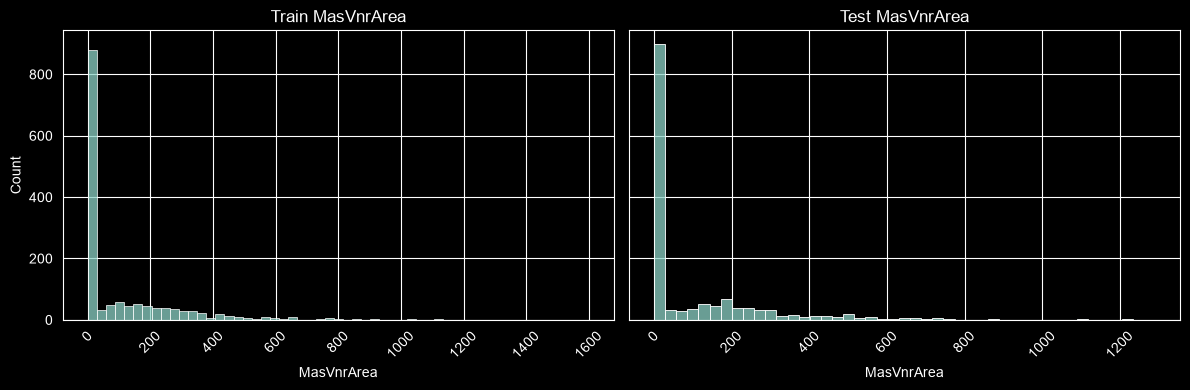

In [1400]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='MasVnrArea', ax=axes[0])
axes[0].set_title('Train MasVnrArea')

sns.histplot(data=df_test, x='MasVnrArea', ax=axes[1])
axes[1].set_title('Test MasVnrArea')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

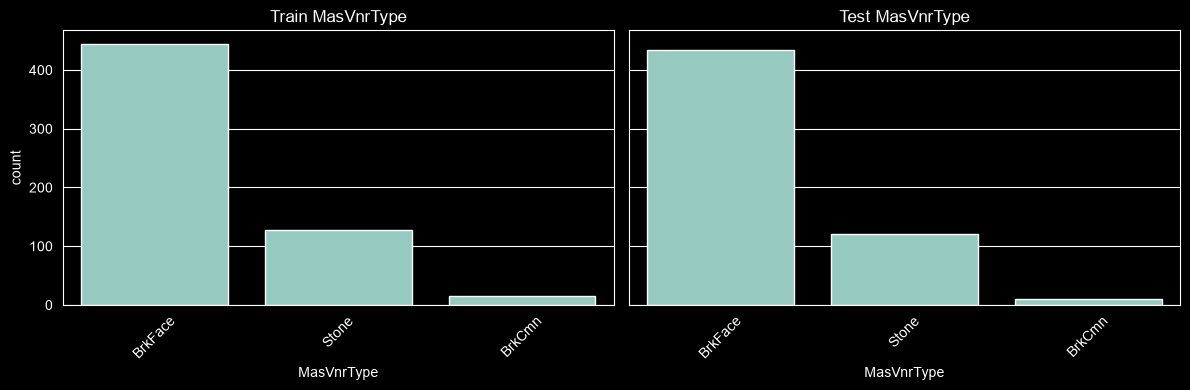

In [1401]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='MasVnrType', ax=axes[0])
axes[0].set_title('Train MasVnrType')

sns.countplot(data=df_test, x='MasVnrType', ax=axes[1])
axes[1].set_title('Test MasVnrType')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1402]:
vnr_mode = df.loc[df['MasVnrArea'] > 0, 'MasVnrType'].dropna().mode()[0]

def process_masvnr(data):
    data['MasVnrArea'] = data['MasVnrArea'].fillna(0)
    data['MasVnrType'] = data['MasVnrType'].fillna('None')

    data.loc[data['MasVnrArea'] == 0, 'MasVnrType'] = 'None'
    data.loc[(data['MasVnrArea'] > 0) & (data['MasVnrType'] == 'None'), 'MasVnrType'] = vnr_mode
    data['Has_MasVnr'] = (data['MasVnrArea'] > 0).astype(int)
    return data

df = process_masvnr(df)
df_test = process_masvnr(df_test)

ExterQual

In [1403]:
print(df['ExterQual'].isnull().sum())
print(df_test['ExterQual'].isnull().sum())

0
0


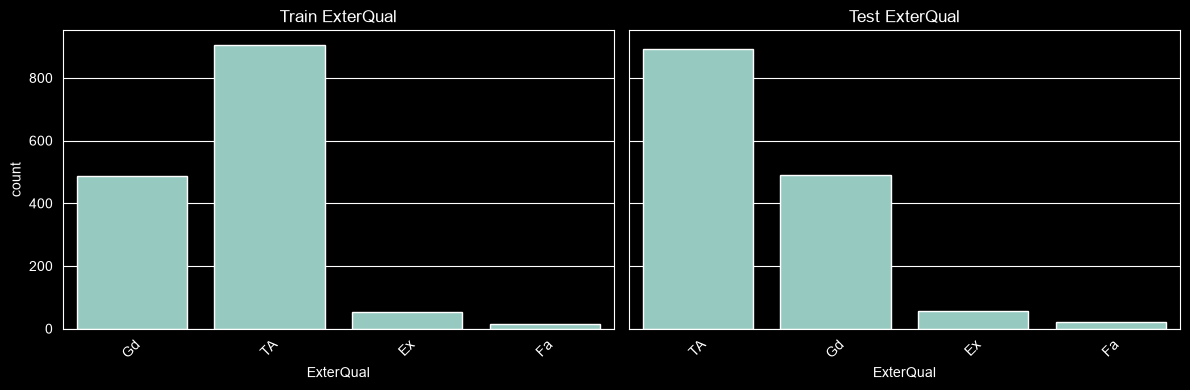

In [1404]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='ExterQual', ax=axes[0])
axes[0].set_title('Train ExterQual')

sns.countplot(data=df_test, x='ExterQual', ax=axes[1])
axes[1].set_title('Test ExterQual')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

ExterCond

In [1405]:
print(df['ExterCond'].isnull().sum())
print(df_test['ExterCond'].isnull().sum())

0
0


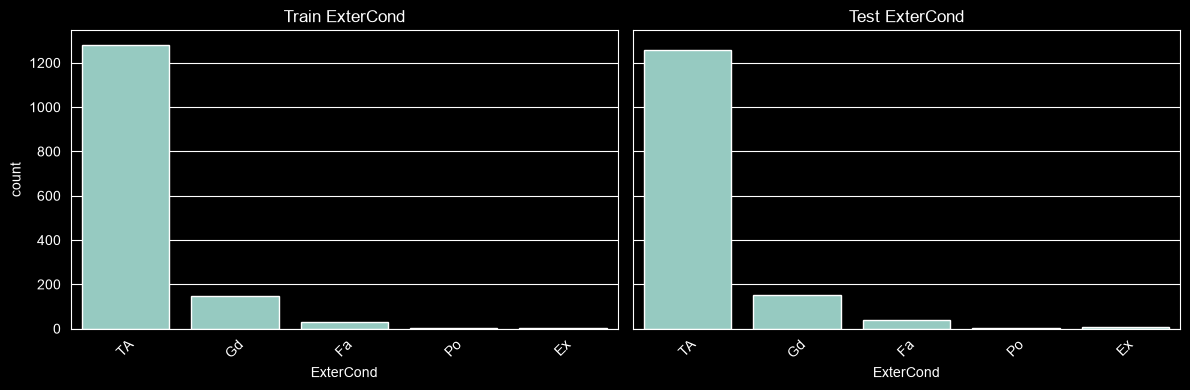

In [1406]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='ExterCond', ax=axes[0])
axes[0].set_title('Train ExterCond')

sns.countplot(data=df_test, x='ExterCond', ax=axes[1])
axes[1].set_title('Test ExterCond')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Foundation

In [1407]:
print(df['Foundation'].isnull().sum())
print(df_test['Foundation'].isnull().sum())

0
0


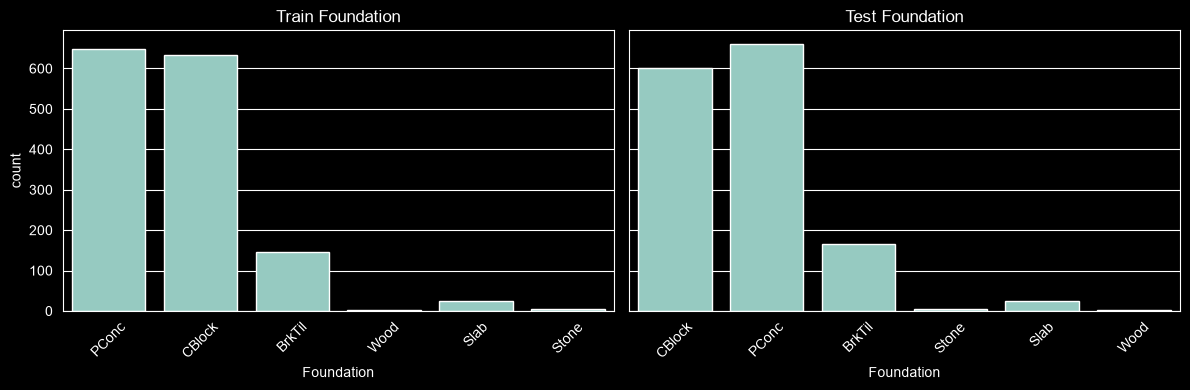

In [1408]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Foundation', ax=axes[0])
axes[0].set_title('Train Foundation')

sns.countplot(data=df_test, x='Foundation', ax=axes[1])
axes[1].set_title('Test Foundation')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Весь подвал(11 фичей подвала это мощно)


In [1409]:
def collapse_bsmt_raw(df_in):
    data = df_in.copy()

    num_cols = ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath']
    for col in num_cols:
        data[col] = data[col].fillna(0)

    cat_cols = ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']
    for col in cat_cols:
        data[col] = data[col].fillna('None')

    data['Has_Bsmt'] = (data['TotalBsmtSF'] > 0).astype(int)
    data['Bsmt_Fin_SF'] = data['BsmtFinSF1'] + data['BsmtFinSF2']
    data['Bsmt_Baths'] = data['BsmtFullBath'] + 0.5 * data['BsmtHalfBath']

    cols_to_drop = ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'BsmtFullBath', 'BsmtHalfBath']

    return data.drop(columns=cols_to_drop)

df = collapse_bsmt_raw(df)
df_test = collapse_bsmt_raw(df_test)

Heating

In [1410]:
print(df['Heating'].isnull().sum())
print(df_test['Heating'].isnull().sum())

0
0


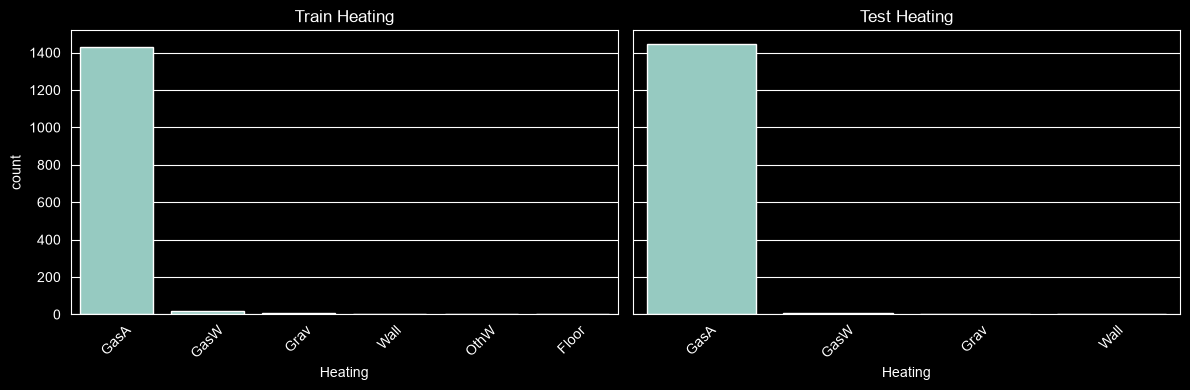

In [1411]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Heating', ax=axes[0])
axes[0].set_title('Train Heating')

sns.countplot(data=df_test, x='Heating', ax=axes[1])
axes[1].set_title('Test Heating')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1412]:
df['Is_GasA'] = (df['Heating'] == 'GasA').astype(int)
df_test['Is_GasA'] = (df_test['Heating'] == 'GasA').astype(int)

df = df.drop(columns=['Heating'])
df_test = df_test.drop(columns=['Heating'])

HeatingQC

In [1413]:
print(df['HeatingQC'].isnull().sum())
print(df_test['HeatingQC'].isnull().sum())

0
0


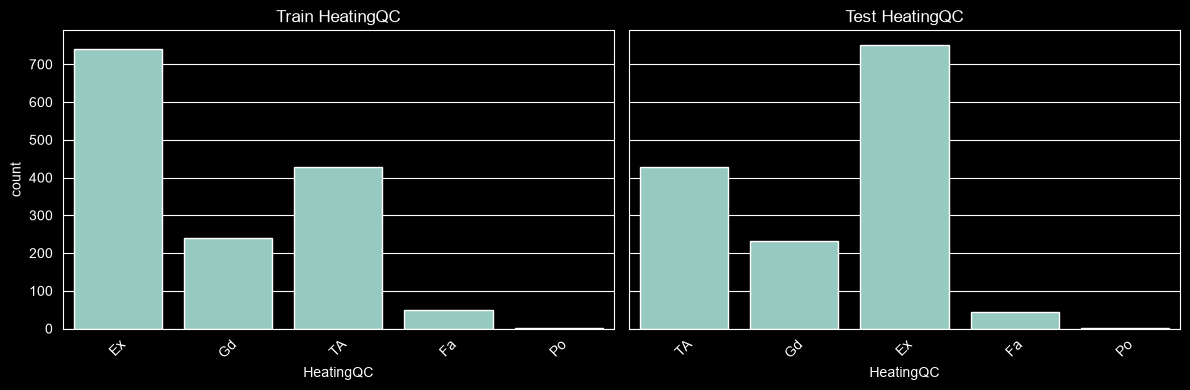

In [1414]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='HeatingQC', ax=axes[0])
axes[0].set_title('Train HeatingQC')

sns.countplot(data=df_test, x='HeatingQC', ax=axes[1])
axes[1].set_title('Test HeatingQC')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

CentralAir

In [1415]:
print(df['CentralAir'].isnull().sum())
print(df_test['CentralAir'].isnull().sum())

0
0


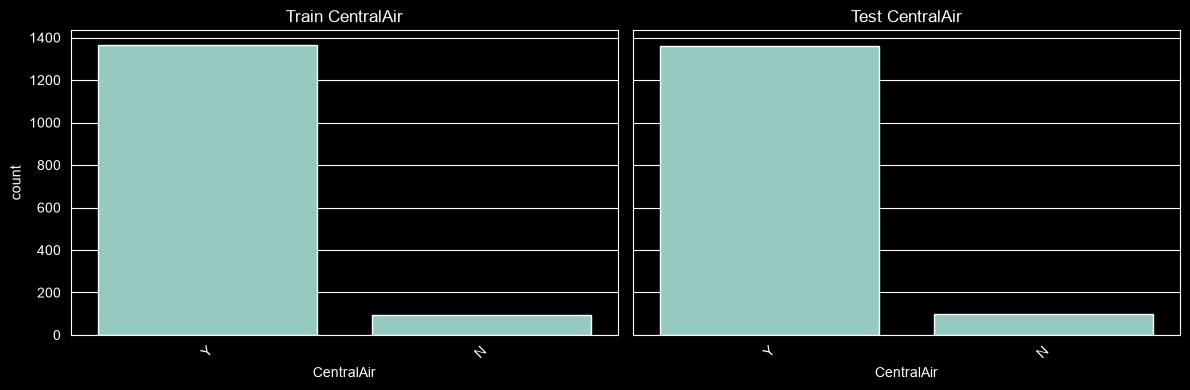

In [1416]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='CentralAir', ax=axes[0])
axes[0].set_title('Train CentralAir')

sns.countplot(data=df_test, x='CentralAir', ax=axes[1])
axes[1].set_title('Test CentralAir')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1417]:
df['CentralAir'] = (df['CentralAir'] == 'Y').astype(int)
df_test['CentralAir'] = (df_test['CentralAir'] == 'Y').astype(int)

Electrical

In [1418]:
print(df['Electrical'].isnull().sum())
print(df_test['Electrical'].isnull().sum())

1
0


In [1419]:
elec_mode = df['Electrical'].mode()[0]

df['Electrical'] = df['Electrical'].fillna(elec_mode)
df_test['Electrical'] = df_test['Electrical'].fillna(elec_mode)


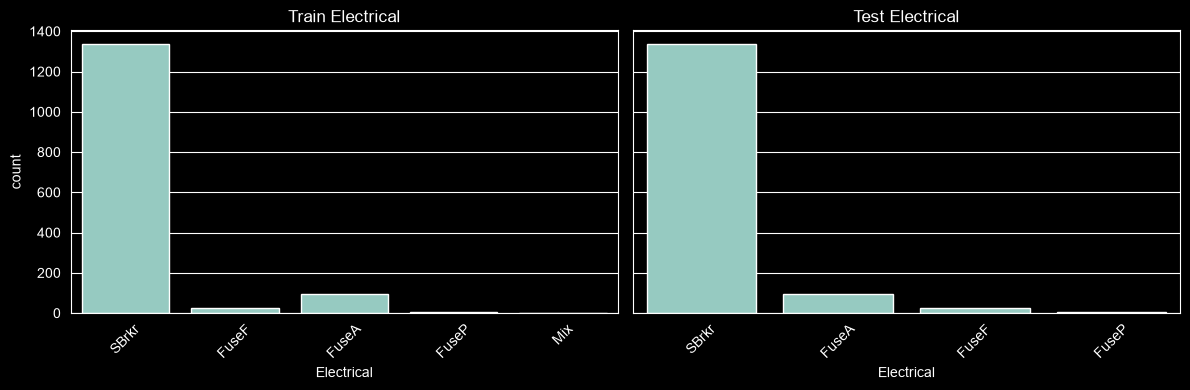

In [1420]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Electrical', ax=axes[0])
axes[0].set_title('Train Electrical')

sns.countplot(data=df_test, x='Electrical', ax=axes[1])
axes[1].set_title('Test Electrical')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1421]:

df['Has_SBrkr'] = (df['Electrical'] == 'SBrkr').astype(int)
df_test['Has_SBrkr'] = (df_test['Electrical'] == 'SBrkr').astype(int)

df = df.drop(columns=['Electrical'])
df_test = df_test.drop(columns=['Electrical'])

1stFlrSF + 2ndFlrSF


In [1422]:
print(df['1stFlrSF'].isnull().sum())
print(df_test['1stFlrSF'].isnull().sum())

0
0


In [1423]:
print(df['2ndFlrSF'].isnull().sum())
print(df_test['2ndFlrSF'].isnull().sum())

0
0


In [1424]:
df['Total_SF'] = df['GrLivArea'] + df['TotalBsmtSF']
df_test['Total_SF'] = df_test['GrLivArea'] + df_test['TotalBsmtSF']

df['Has_2ndFlr'] = (df['2ndFlrSF'] > 0).astype(int)
df_test['Has_2ndFlr'] = (df_test['2ndFlrSF'] > 0).astype(int)



LowQualFinSF

In [1425]:
print(df['LowQualFinSF'].isnull().sum())
print(df_test['LowQualFinSF'].isnull().sum())

0
0


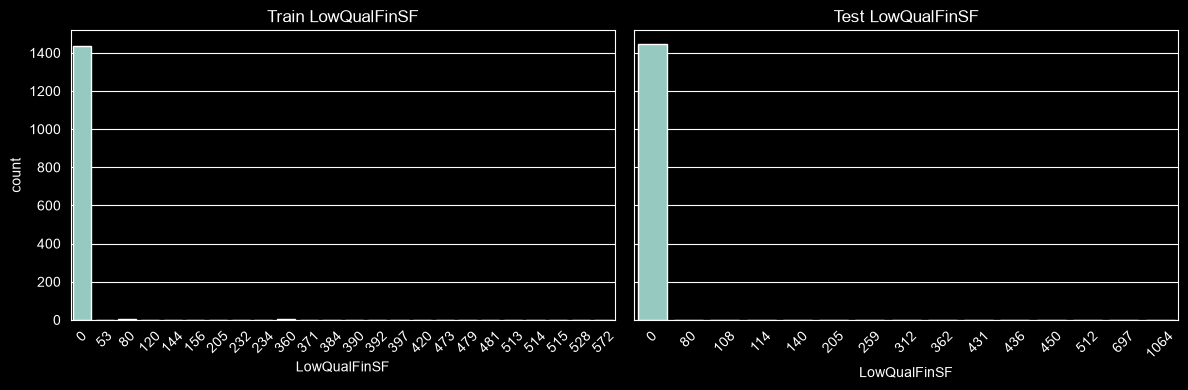

In [1426]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='LowQualFinSF', ax=axes[0])
axes[0].set_title('Train LowQualFinSF')

sns.countplot(data=df_test, x='LowQualFinSF', ax=axes[1])
axes[1].set_title('Test LowQualFinSF')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1427]:
df['Has_LowQualFin'] = (df['LowQualFinSF'] > 0).astype(int)
df_test['Has_LowQualFin'] = (df_test['LowQualFinSF'] > 0).astype(int)

df = df.drop(columns=['LowQualFinSF'])
df_test = df_test.drop(columns=['LowQualFinSF'])

GrLivArea

In [1428]:
print(df['GrLivArea'].isnull().sum())
print(df_test['GrLivArea'].isnull().sum())

0
0


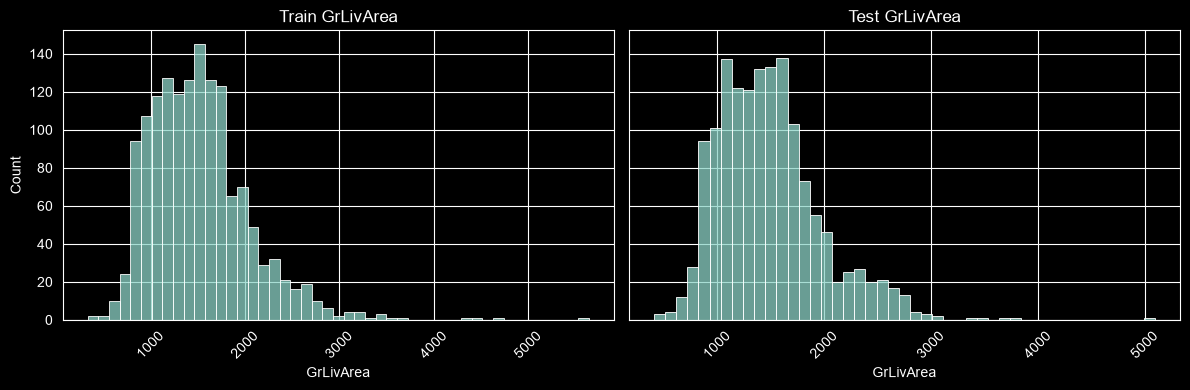

In [1429]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='GrLivArea', ax=axes[0])
axes[0].set_title('Train GrLivArea')

sns.histplot(data=df_test, x='GrLivArea', ax=axes[1])
axes[1].set_title('Test GrLivArea')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

TotRmsAbvGrd

In [1430]:
print(df['TotRmsAbvGrd'].isnull().sum())
print(df_test['TotRmsAbvGrd'].isnull().sum())

0
0


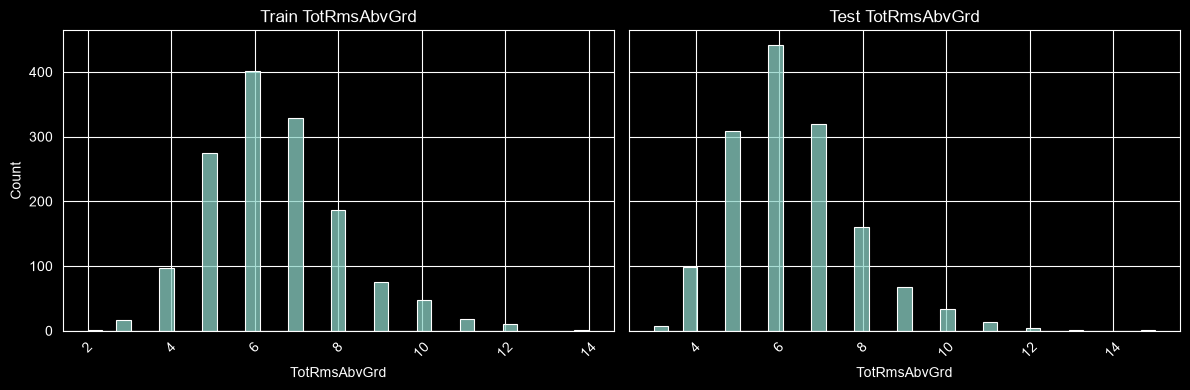

In [1431]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='TotRmsAbvGrd', ax=axes[0])
axes[0].set_title('Train TotRmsAbvGrd')

sns.histplot(data=df_test, x='TotRmsAbvGrd', ax=axes[1])
axes[1].set_title('Test TotRmsAbvGrd')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1432]:
df['Avg_Room_SF'] = df['GrLivArea'] / df['TotRmsAbvGrd']
df_test['Avg_Room_SF'] = df_test['GrLivArea'] / df_test['TotRmsAbvGrd']

FullBath

In [1433]:
print(df['FullBath'].isnull().sum())
print(df_test['FullBath'].isnull().sum())

0
0


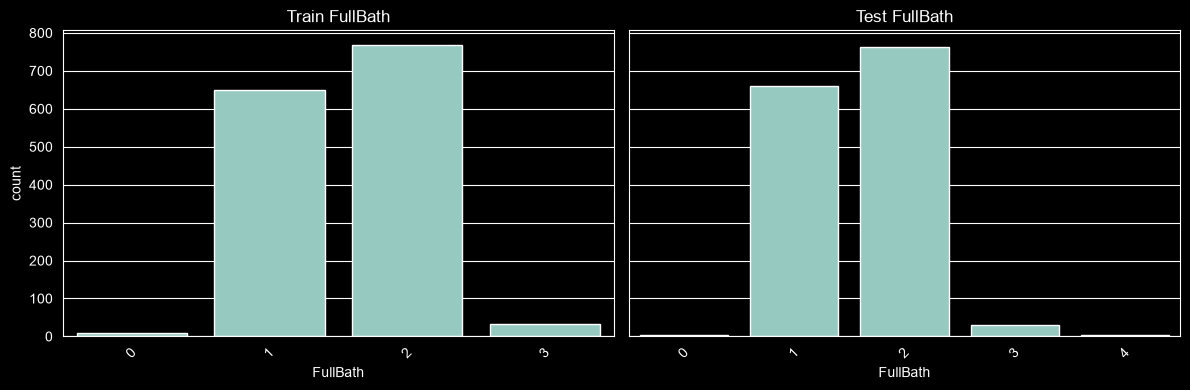

In [1434]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='FullBath', ax=axes[0])
axes[0].set_title('Train FullBath')

sns.countplot(data=df_test, x='FullBath', ax=axes[1])
axes[1].set_title('Test FullBath')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

HalfBath

In [1435]:
print(df['HalfBath'].isnull().sum())
print(df_test['HalfBath'].isnull().sum())

0
0


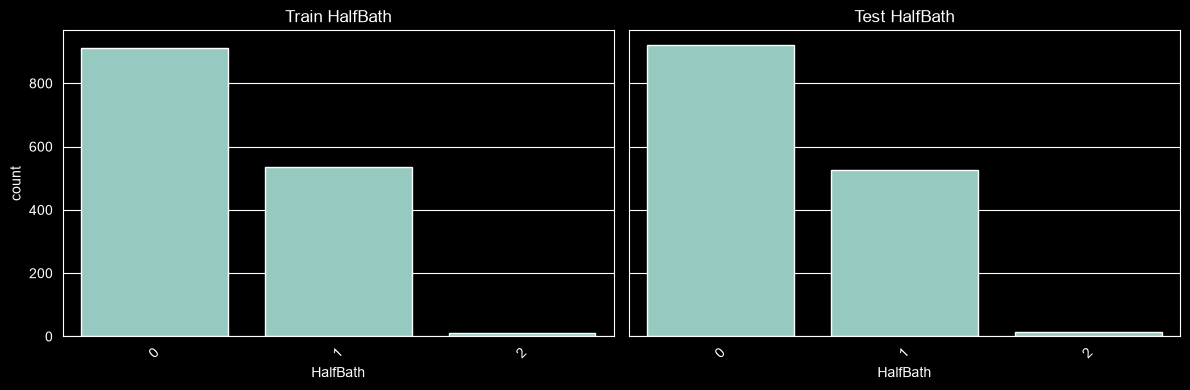

In [1436]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='HalfBath', ax=axes[0])
axes[0].set_title('Train HalfBath')

sns.countplot(data=df_test, x='HalfBath', ax=axes[1])
axes[1].set_title('Test HalfBath')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1437]:
df['AbvGrd_Baths'] = df['FullBath'] + 0.5 * df['HalfBath']
df_test['AbvGrd_Baths'] = df_test['FullBath'] + 0.5 * df_test['HalfBath']

df['Total_Baths'] = df['AbvGrd_Baths'] + df['Bsmt_Baths']
df_test['Total_Baths'] = df_test['AbvGrd_Baths'] + df_test['Bsmt_Baths']

df = df.drop(columns=['FullBath', 'HalfBath'])
df_test = df_test.drop(columns=['FullBath', 'HalfBath'])

Bedroom

In [1438]:
# print(df['Bedroom'].isnull().sum())
# print(df_test['Bedroom'].isnull().sum())

In [1439]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Alley',
       'LotShape', 'LandContour', 'LotConfig', 'LandSlope', 'Neighborhood',
       'BldgType', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea',
       'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond',
       'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'TotalBsmtSF',
       'HeatingQC', 'CentralAir', '1stFlrSF', '2ndFlrSF', 'GrLivArea',
       'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd',
       'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt',
       'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond',
       'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch',
       'ScreenPorch', 'PoolArea', 'PoolQC', 'Fence', 'MiscFeature', 'MiscVal',
       'MoSold', 'YrSold', 'SaleType', 'SaleCondition', 'SalePrice',
       'Is_Regular_Lot', '

In [1440]:
print(df['BedroomAbvGr'].isna().sum())
print(df_test['BedroomAbvGr'].isna().sum())

0
0


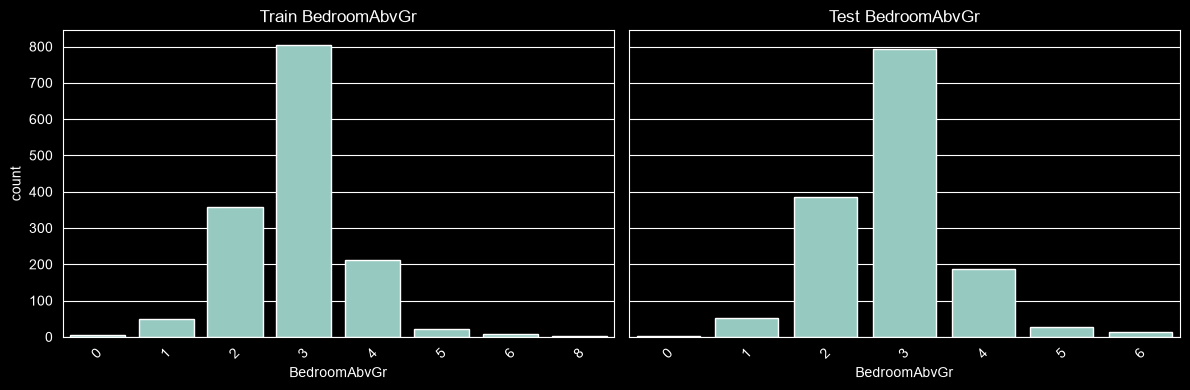

In [1441]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='BedroomAbvGr', ax=axes[0])
axes[0].set_title('Train BedroomAbvGr')

sns.countplot(data=df_test, x='BedroomAbvGr', ax=axes[1])
axes[1].set_title('Test BedroomAbvGr')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Kitchen

In [1442]:
print(df['KitchenAbvGr'].isna().sum())
print(df_test['KitchenAbvGr'].isna().sum())

0
0


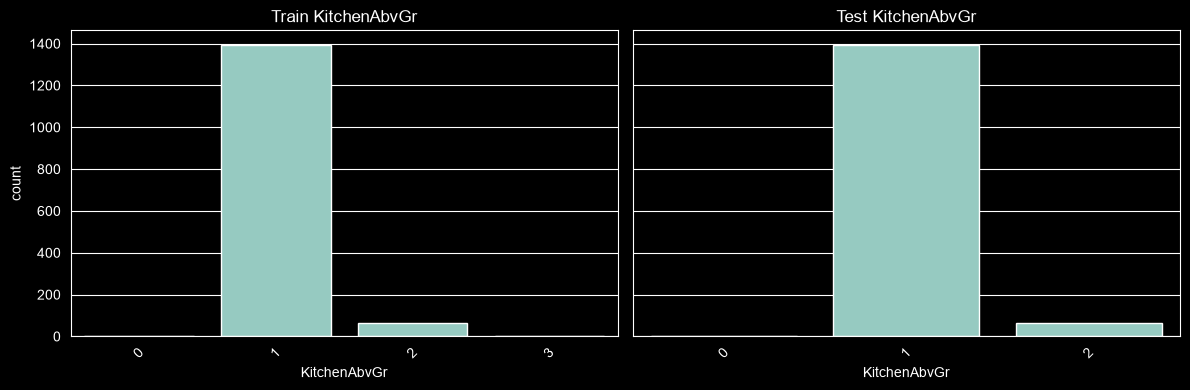

In [1443]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='KitchenAbvGr', ax=axes[0])
axes[0].set_title('Train KitchenAbvGr')

sns.countplot(data=df_test, x='KitchenAbvGr', ax=axes[1])
axes[1].set_title('Test KitchenAbvGr')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1444]:
df['Other_Rms_AbvGrd'] = df['TotRmsAbvGrd'] - df['BedroomAbvGr'] - df['KitchenAbvGr']
df_test['Other_Rms_AbvGrd'] = df_test['TotRmsAbvGrd'] - df_test['BedroomAbvGr'] - df_test['KitchenAbvGr']

KitchenQual

In [1445]:
print(df['KitchenQual'].isna().sum())
print(df_test['KitchenQual'].isna().sum())

0
1


In [1446]:
global_mode = df['KitchenQual'].mode()[0]
neigh_mode = df.groupby('Neighborhood')['KitchenQual'].apply(lambda x: x.mode()[0] if not x.mode().empty else global_mode)

df_test['KitchenQual'] = df_test['KitchenQual'].fillna(df_test['Neighborhood'].map(neigh_mode))

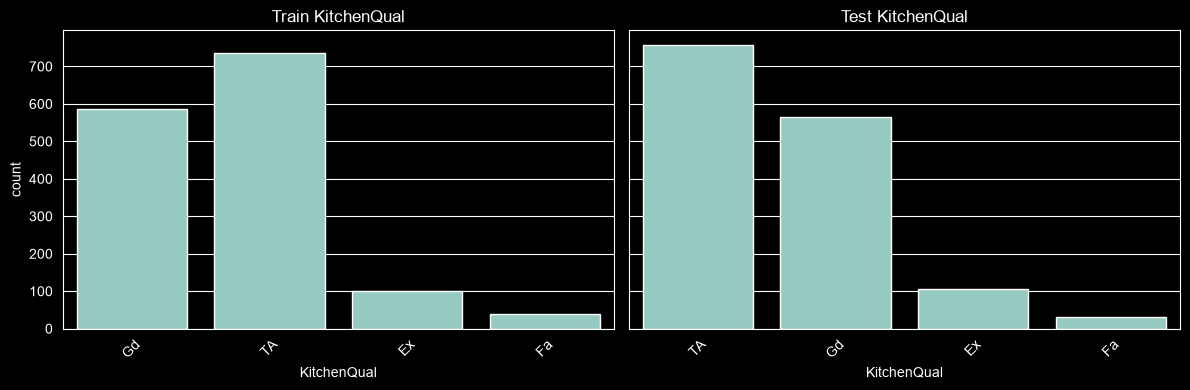

In [1447]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='KitchenQual', ax=axes[0])
axes[0].set_title('Train KitchenQual')

sns.countplot(data=df_test, x='KitchenQual', ax=axes[1])
axes[1].set_title('Test KitchenQual')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Fireplaces

In [1448]:
print(df['Fireplaces'].isna().sum())
print(df_test['Fireplaces'].isna().sum())

0
0


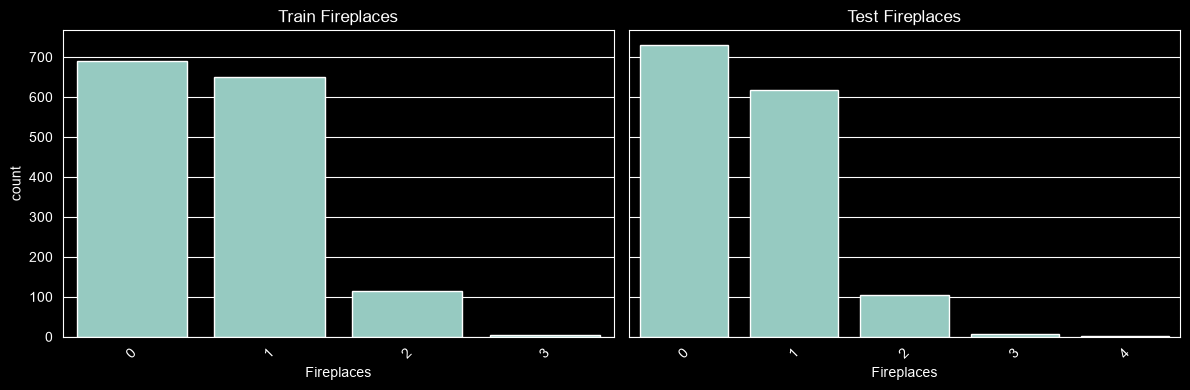

In [1449]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Fireplaces', ax=axes[0])
axes[0].set_title('Train Fireplaces')

sns.countplot(data=df_test, x='Fireplaces', ax=axes[1])
axes[1].set_title('Test Fireplaces')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1450]:
df['Fireplaces'] = df['Fireplaces'].clip(upper=2)
df_test['Fireplaces'] = df_test['Fireplaces'].clip(upper=2)



FireplaceQu

In [1453]:
print(df['FireplaceQu'].isna().sum())
print(df_test['FireplaceQu'].isna().sum())

690
730


In [1455]:
df['FireplaceQu'] = df['FireplaceQu'].fillna('None')
df_test['FireplaceQu'] = df_test['FireplaceQu'].fillna('None')

df.loc[df['Fireplaces'] == 0, 'FireplaceQu'] = 'None'
df_test.loc[df_test['Fireplaces'] == 0, 'FireplaceQu'] = 'None'

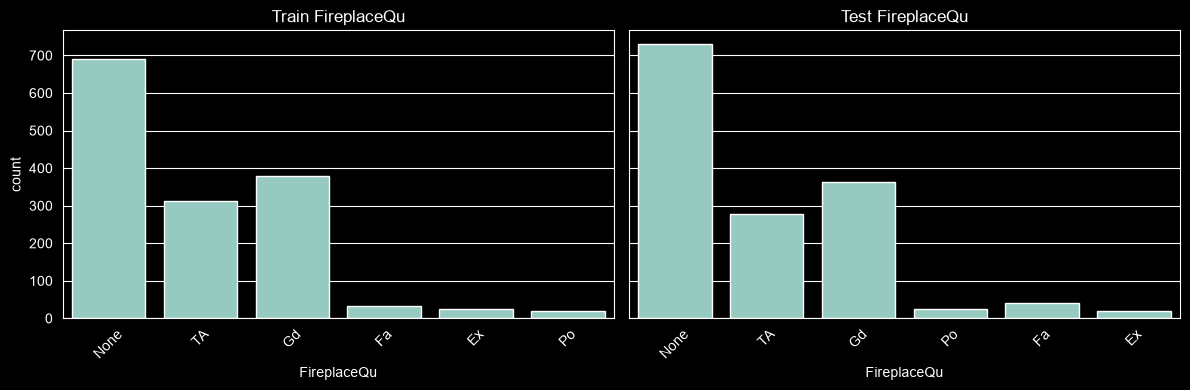

In [1456]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='FireplaceQu', ax=axes[0])
axes[0].set_title('Train FireplaceQu')

sns.countplot(data=df_test, x='FireplaceQu', ax=axes[1])
axes[1].set_title('Test FireplaceQu')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

GarageArea

In [1457]:
print(df['GarageArea'].isna().sum())
print(df_test['GarageArea'].isna().sum())

0
1


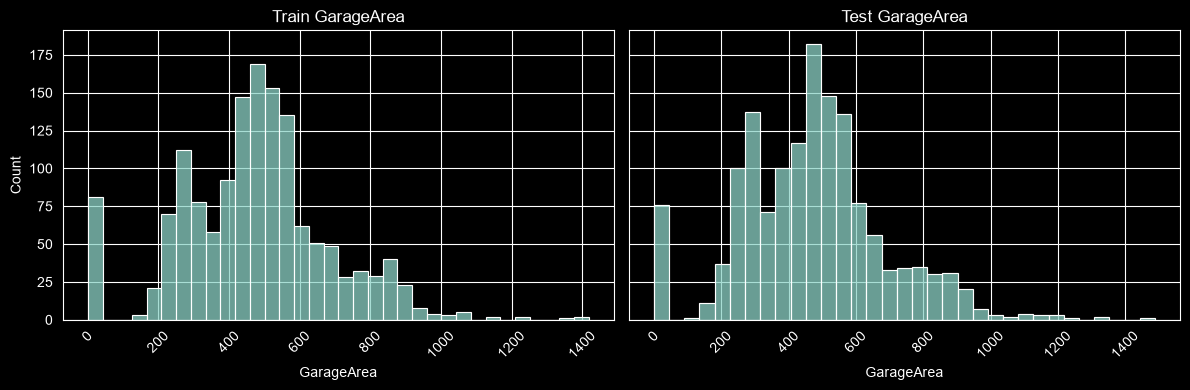

In [1459]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='GarageArea', ax=axes[0])
axes[0].set_title('Train GarageArea')

sns.histplot(data=df_test, x='GarageArea', ax=axes[1])
axes[1].set_title('Test GarageArea')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

GarageCars

In [1460]:
print(df['GarageCars'].isna().sum())
print(df_test['GarageCars'].isna().sum())

0
1


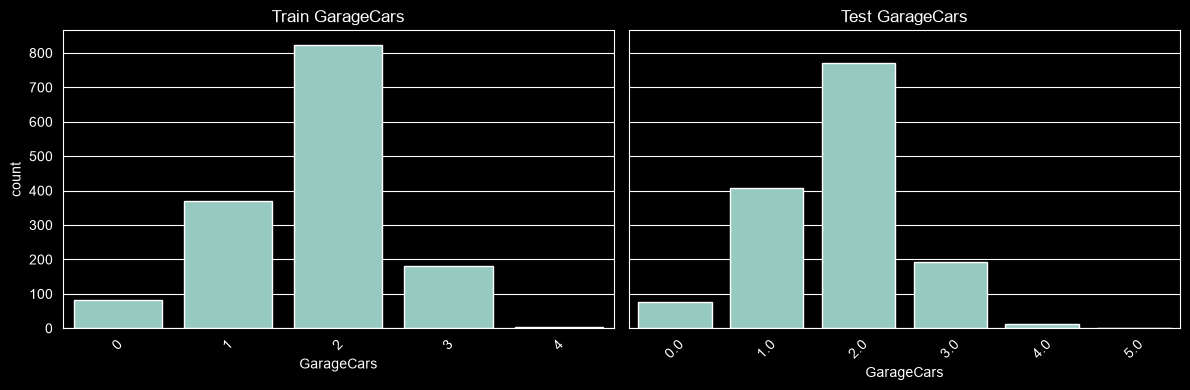

In [1462]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='GarageCars', ax=axes[0])
axes[0].set_title('Train GarageCars')

sns.countplot(data=df_test, x='GarageCars', ax=axes[1])
axes[1].set_title('Test GarageCars')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

GarageQual

In [1463]:
print(df['GarageQual'].isna().sum())
print(df_test['GarageQual'].isna().sum())

81
78


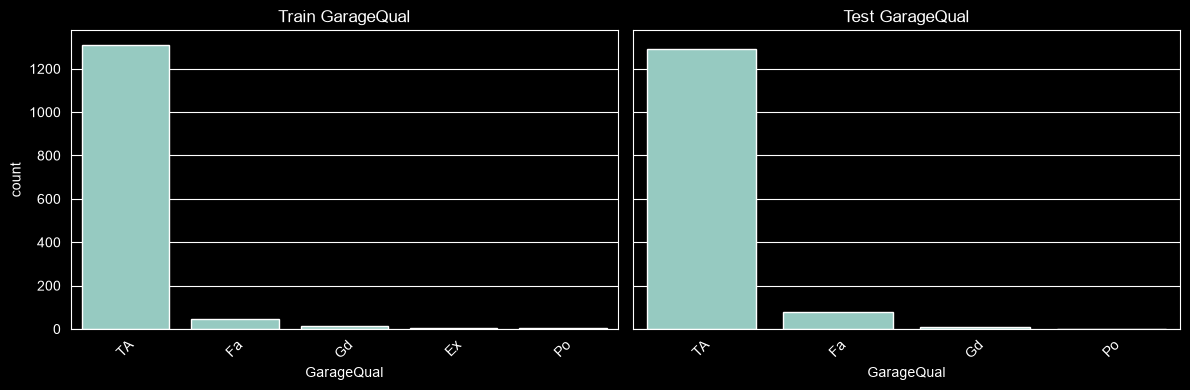

In [1465]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='GarageQual', ax=axes[0])
axes[0].set_title('Train GarageQual')

sns.countplot(data=df_test, x='GarageQual', ax=axes[1])
axes[1].set_title('Test GarageQual')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

GarageType

In [1466]:
print(df['GarageType'].isna().sum())
print(df_test['GarageType'].isna().sum())

81
76


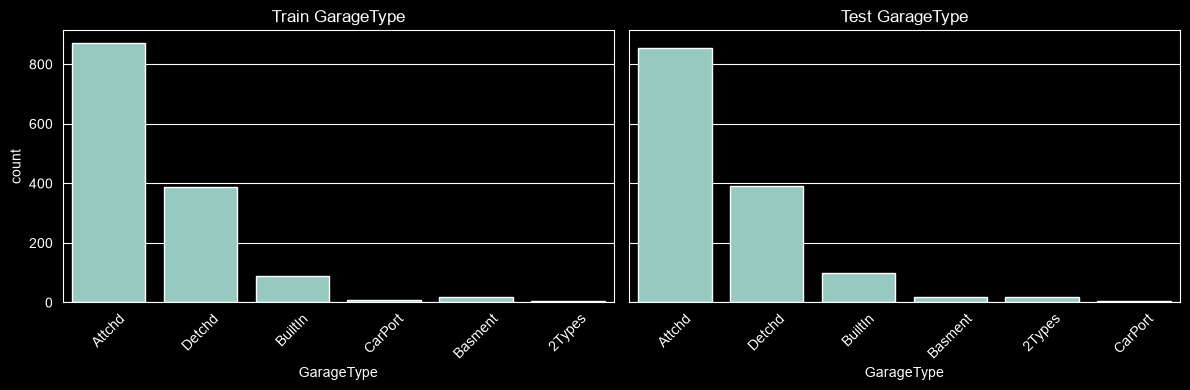

In [1468]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='GarageType', ax=axes[0])
axes[0].set_title('Train GarageType')

sns.countplot(data=df_test, x='GarageType', ax=axes[1])
axes[1].set_title('Test GarageType')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

GarageYrBlt

In [1469]:
print(df['GarageYrBlt'].isna().sum())
print(df_test['GarageYrBlt'].isna().sum())

81
78


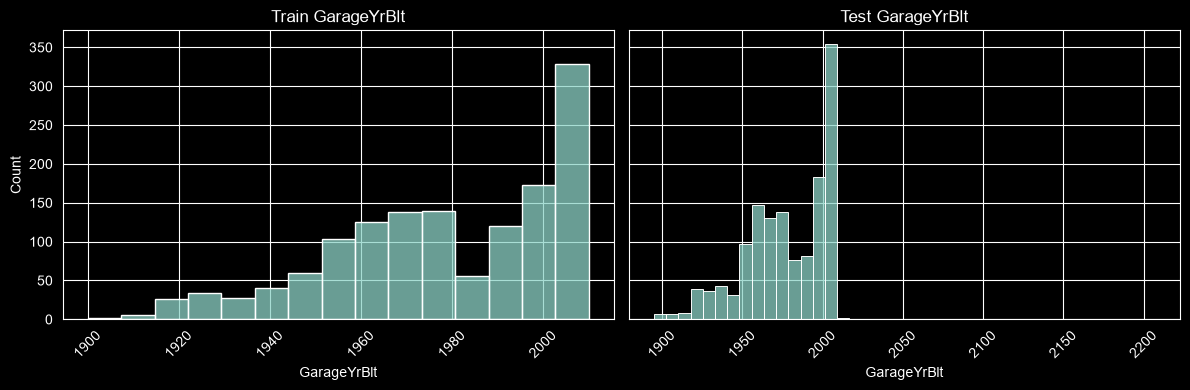

In [1471]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='GarageYrBlt', ax=axes[0])
axes[0].set_title('Train GarageYrBlt')

sns.histplot(data=df_test, x='GarageYrBlt', ax=axes[1])
axes[1].set_title('Test GarageYrBlt')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

GarageFinish

In [1472]:
print(df['GarageFinish'].isna().sum())
print(df_test['GarageFinish'].isna().sum())

81
78


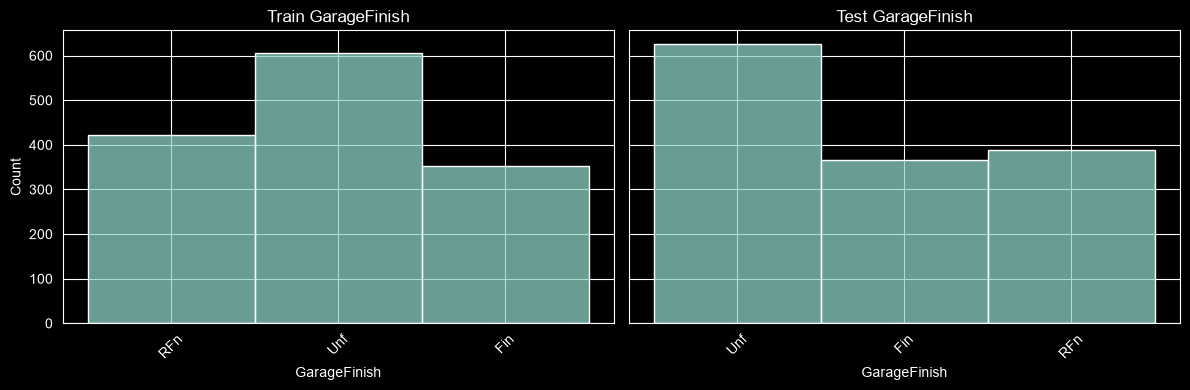

In [1473]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='GarageFinish', ax=axes[0])
axes[0].set_title('Train GarageFinish')

sns.histplot(data=df_test, x='GarageFinish', ax=axes[1])
axes[1].set_title('Test GarageFinish')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

GarageCond

In [1474]:
print(df['GarageCond'].isna().sum())
print(df_test['GarageCond'].isna().sum())

81
78


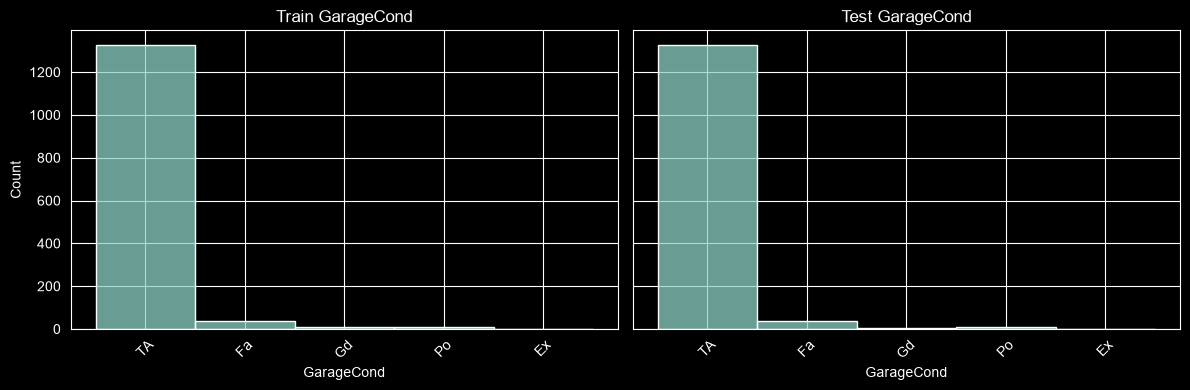

In [1475]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='GarageCond', ax=axes[0])
axes[0].set_title('Train GarageCond')

sns.histplot(data=df_test, x='GarageCond', ax=axes[1])
axes[1].set_title('Test GarageCond')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1476]:
def process_garage_block(df_in):
    data = df_in.copy()

    for col in ['GarageCars', 'GarageArea']:
        data[col] = data[col].fillna(0)

    mask_no_garage = (data['GarageCars'] == 0) | (data['GarageArea'] == 0)

    data.loc[mask_no_garage, 'GarageCars'] = 0
    data.loc[mask_no_garage, 'GarageArea'] = 0

    cat_cols = ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']
    for col in cat_cols:
        data.loc[mask_no_garage, col] = 'None'

    data['GarageYrBlt'] = data['GarageYrBlt'].fillna(data['YearBuilt'])
    data.loc[data['GarageYrBlt'] > 2010, 'GarageYrBlt'] = data.loc[data['GarageYrBlt'] > 2010, 'YearBuilt']

    for col in cat_cols:
        if data[col].isna().sum() > 0:
            mode_val = data[col].mode()[0]
            data[col] = data[col].fillna(mode_val)

    data['Area_Per_Car'] = (data['GarageArea'] / data['GarageCars']).fillna(0).replace([np.inf, -np.inf], 0)

    return data

df = process_garage_block(df)
df_test = process_garage_block(df_test)

PavedDrive

In [1477]:
print(df['PavedDrive'].isna().sum())
print(df_test['PavedDrive'].isna().sum())

0
0


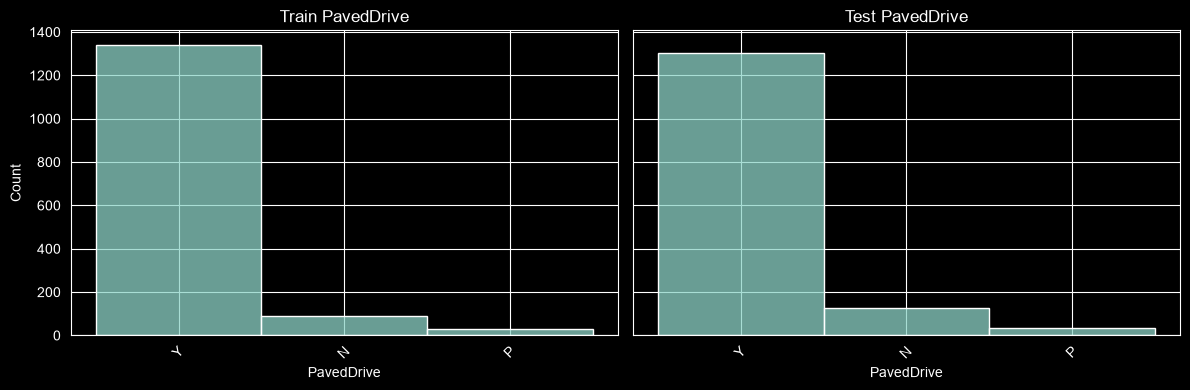

In [1478]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='PavedDrive', ax=axes[0])
axes[0].set_title('Train PavedDrive')

sns.histplot(data=df_test, x='PavedDrive', ax=axes[1])
axes[1].set_title('Test PavedDrive')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

WoodDeckSF

In [1479]:
print(df['WoodDeckSF'].isna().sum())
print(df_test['WoodDeckSF'].isna().sum())

0
0


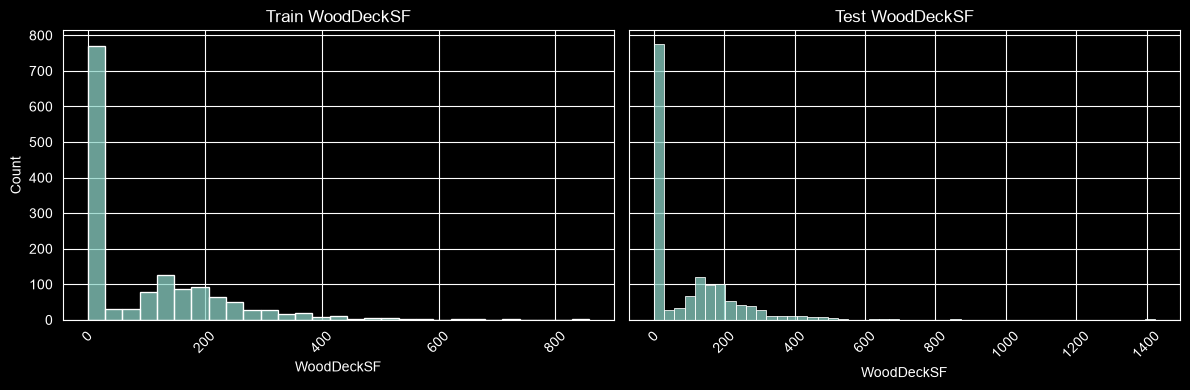

In [1484]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='WoodDeckSF', ax=axes[0])
axes[0].set_title('Train WoodDeckSF')

sns.histplot(data=df_test, x='WoodDeckSF', ax=axes[1])
axes[1].set_title('Test WoodDeckSF')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

OpenPorchSF

In [1480]:
print(df['OpenPorchSF'].isna().sum())
print(df_test['OpenPorchSF'].isna().sum())

0
0


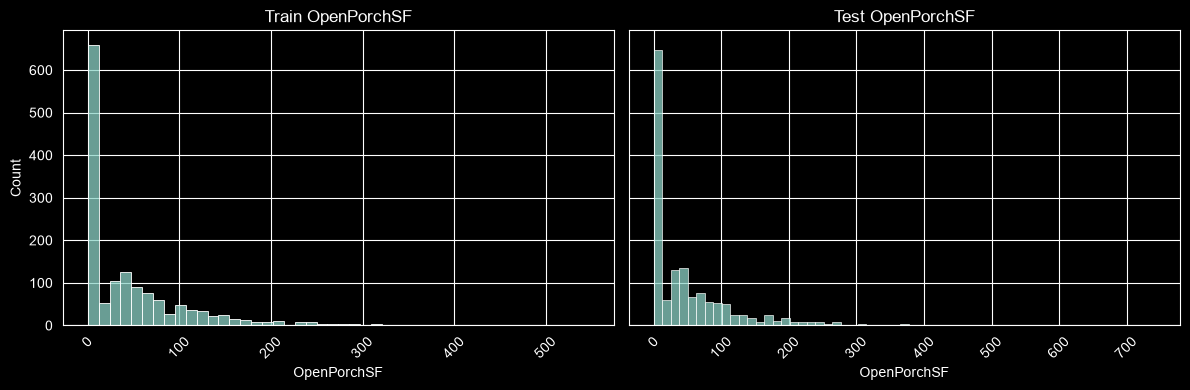

In [1485]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='OpenPorchSF', ax=axes[0])
axes[0].set_title('Train OpenPorchSF')

sns.histplot(data=df_test, x='OpenPorchSF', ax=axes[1])
axes[1].set_title('Test OpenPorchSF')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

EnclosedPorch

In [1481]:
print(df['EnclosedPorch'].isna().sum())
print(df_test['EnclosedPorch'].isna().sum())

0
0


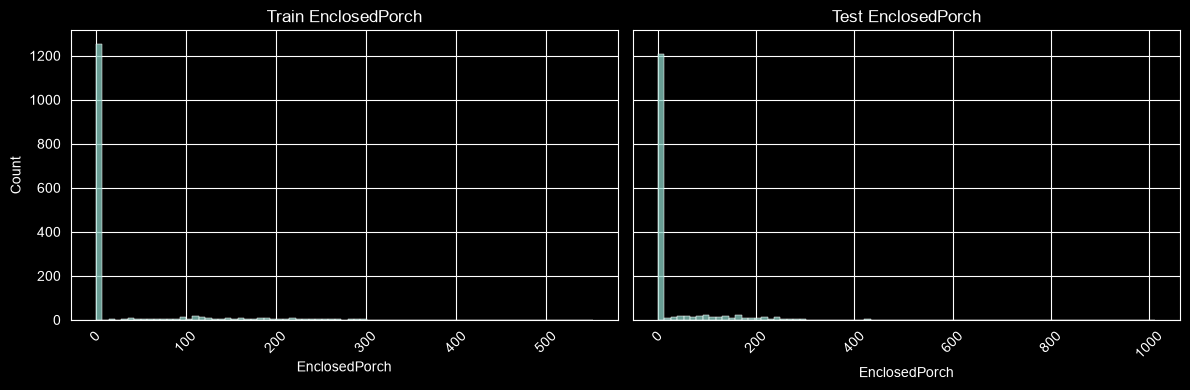

In [1486]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='EnclosedPorch', ax=axes[0])
axes[0].set_title('Train EnclosedPorch')

sns.histplot(data=df_test, x='EnclosedPorch', ax=axes[1])
axes[1].set_title('Test EnclosedPorch')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

3SsnPorch

In [1482]:
print(df['3SsnPorch'].isna().sum())
print(df_test['3SsnPorch'].isna().sum())

0
0


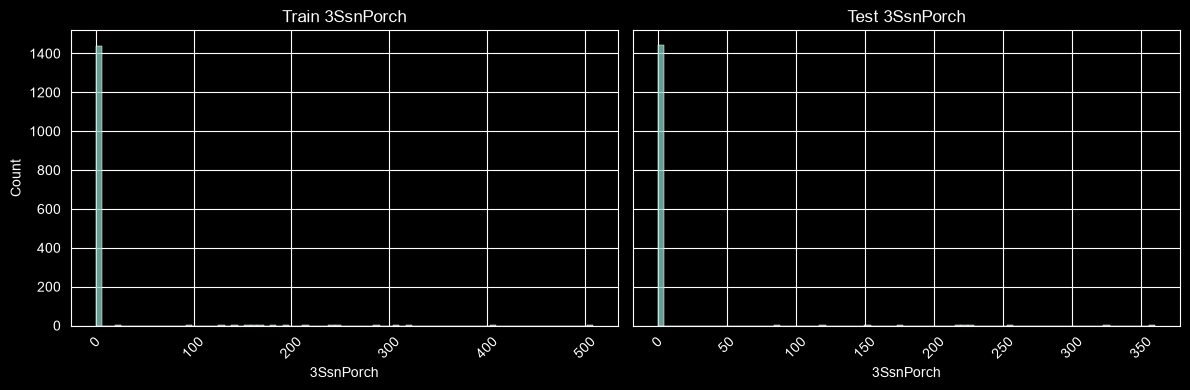

In [1487]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='3SsnPorch', ax=axes[0])
axes[0].set_title('Train 3SsnPorch')

sns.histplot(data=df_test, x='3SsnPorch', ax=axes[1])
axes[1].set_title('Test 3SsnPorch')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

ScreenPorch

In [1483]:
print(df['ScreenPorch'].isna().sum())
print(df_test['ScreenPorch'].isna().sum())

0
0


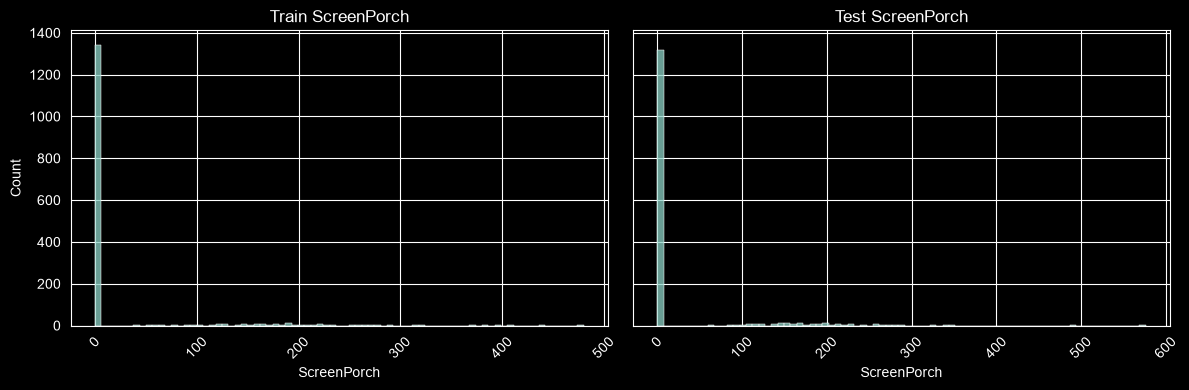

In [1488]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='ScreenPorch', ax=axes[0])
axes[0].set_title('Train ScreenPorch')

sns.histplot(data=df_test, x='ScreenPorch', ax=axes[1])
axes[1].set_title('Test ScreenPorch')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1489]:
porch_cols = ['WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch']

df['Total_Porch_SF'] = df[porch_cols].sum(axis=1)
df_test['Total_Porch_SF'] = df_test[porch_cols].sum(axis=1)

df = df.drop(columns=['EnclosedPorch', '3SsnPorch', 'ScreenPorch'])
df_test = df_test.drop(columns=['EnclosedPorch', '3SsnPorch', 'ScreenPorch'])

PoolArea

In [1490]:
print(df['PoolArea'].isna().sum())
print(df_test['PoolArea'].isna().sum())

0
0


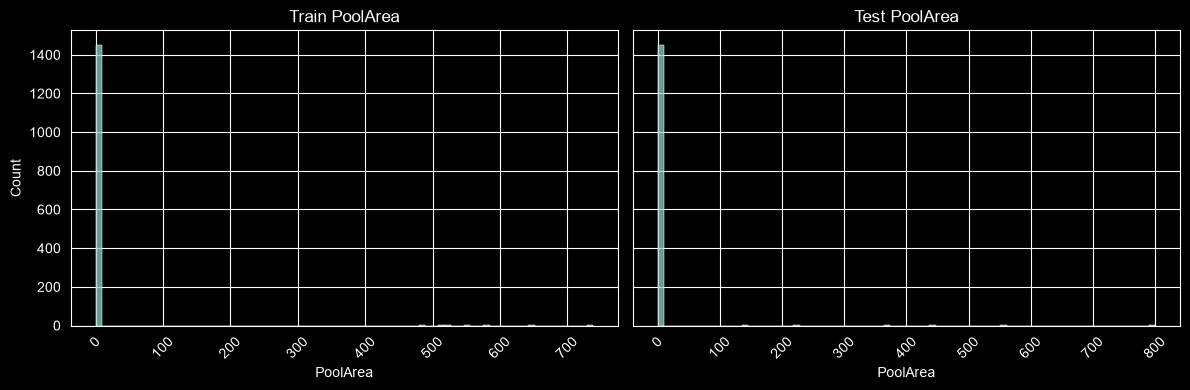

In [1491]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='PoolArea', ax=axes[0])
axes[0].set_title('Train PoolArea')

sns.histplot(data=df_test, x='PoolArea', ax=axes[1])
axes[1].set_title('Test PoolArea')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1492]:
df['Has_Pool'] = (df['PoolArea'] > 0).astype(int)
df_test['Has_Pool'] = (df_test['PoolArea'] > 0).astype(int)

df = df.drop(columns=['PoolArea', 'PoolQC'])
df_test = df_test.drop(columns=['PoolArea', 'PoolQC'])

Fence

In [1494]:
print(df['Fence'].isna().sum())
print(df_test['Fence'].isna().sum())

1179
1169


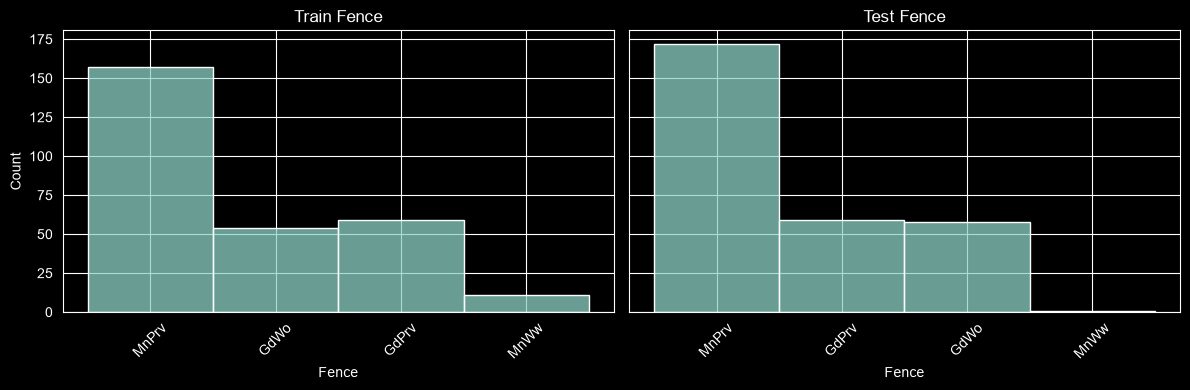

In [1495]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='Fence', ax=axes[0])
axes[0].set_title('Train Fence')

sns.histplot(data=df_test, x='Fence', ax=axes[1])
axes[1].set_title('Test Fence')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1496]:
df['Fence'] = df['Fence'].fillna('None')
df_test['Fence'] = df_test['Fence'].fillna('None')

MiscFeature

In [1497]:
print(df['MiscFeature'].isna().sum())
print(df_test['MiscFeature'].isna().sum())

1406
1408


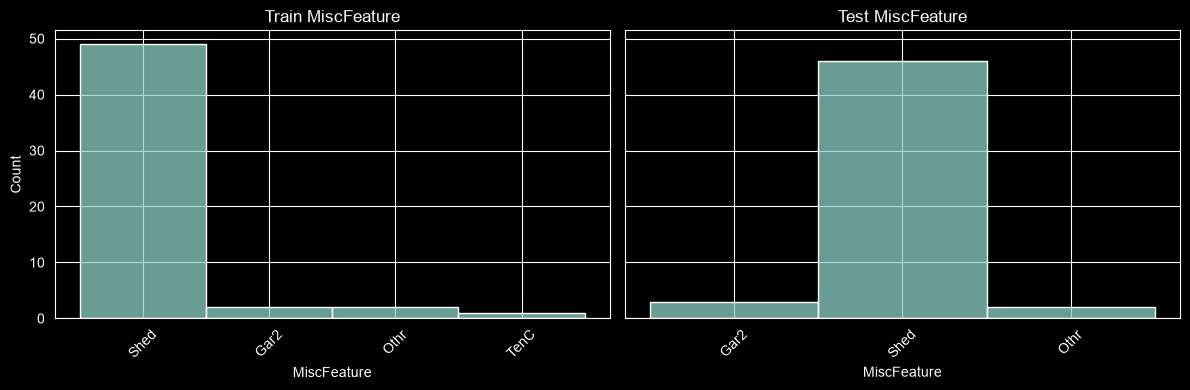

In [1498]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='MiscFeature', ax=axes[0])
axes[0].set_title('Train MiscFeature')

sns.histplot(data=df_test, x='MiscFeature', ax=axes[1])
axes[1].set_title('Test MiscFeature')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1499]:
df['Has_Shed'] = (df['MiscFeature'] == 'Shed').astype(int)
df_test['Has_Shed'] = (df_test['MiscFeature'] == 'Shed').astype(int)

df = df.drop(columns=['MiscFeature', 'MiscVal'])
df_test = df_test.drop(columns=['MiscFeature', 'MiscVal'])

MoSold

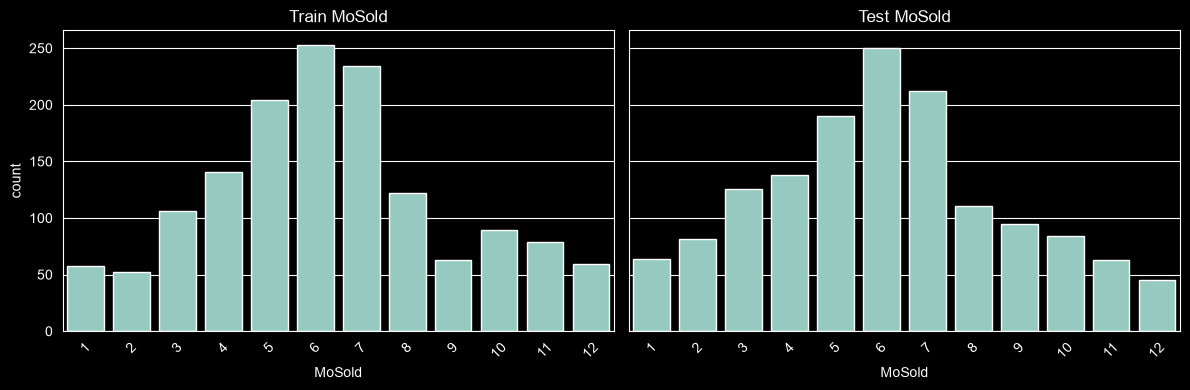

In [1502]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='MoSold', ax=axes[0])
axes[0].set_title('Train MoSold')

sns.countplot(data=df_test, x='MoSold', ax=axes[1])
axes[1].set_title('Test MoSold')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1500]:
print(df['MoSold'].isna().sum())
print(df_test['MoSold'].isna().sum())

0
0


In [1503]:
df['MoSold_Sin'] = np.sin(2 * np.pi * df['MoSold'] / 12)
df['MoSold_Cos'] = np.cos(2 * np.pi * df['MoSold'] / 12)

df_test['MoSold_Sin'] = np.sin(2 * np.pi * df_test['MoSold'] / 12)
df_test['MoSold_Cos'] = np.cos(2 * np.pi * df_test['MoSold'] / 12)

df['Is_Peak_Season'] = df['MoSold'].isin([5, 6, 7]).astype(int)
df_test['Is_Peak_Season'] = df_test['MoSold'].isin([5, 6, 7]).astype(int)

In [1504]:
df = df.drop(columns=['MoSold'])
df_test = df_test.drop(columns=['MoSold'])

YrSold

In [1506]:
print(df['YrSold'].isna().sum())
print(df_test['YrSold'].isna().sum())

0
0


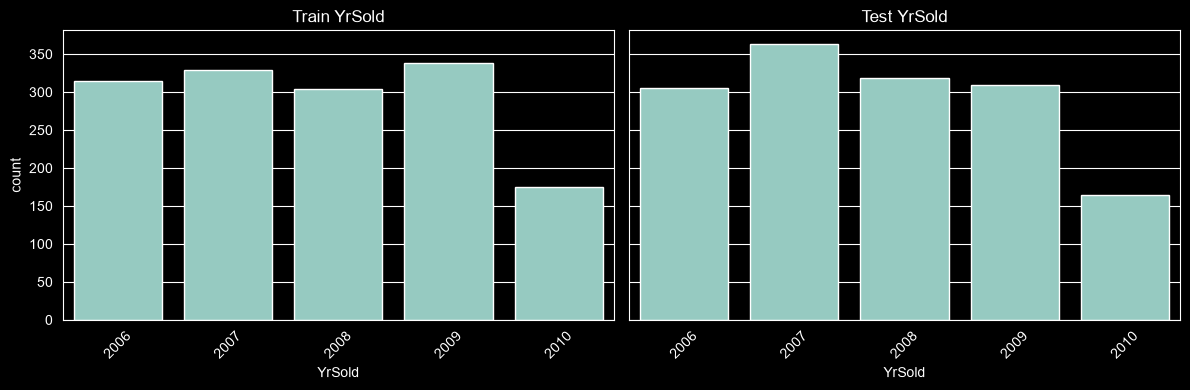

In [1509]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='YrSold', ax=axes[0])
axes[0].set_title('Train YrSold')

sns.countplot(data=df_test, x='YrSold', ax=axes[1])
axes[1].set_title('Test YrSold')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

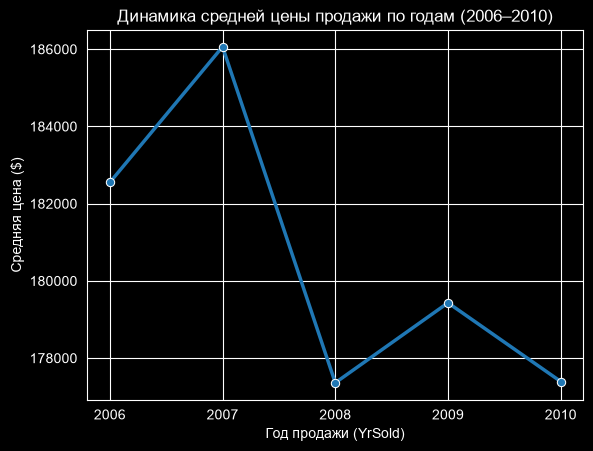

In [1510]:
plt.figure()
yearly_avg = df.groupby('YrSold')['SalePrice'].mean().reset_index()
sns.lineplot(
    data=yearly_avg,
    x='YrSold',
    y='SalePrice',
    marker='o',
    linewidth=2.5,
    color='#1f77b4'
)

plt.title('Динамика средней цены продажи по годам (2006–2010)')
plt.xlabel('Год продажи (YrSold)')
plt.ylabel('Средняя цена ($)')
plt.xticks(yearly_avg['YrSold'].unique())
plt.show()

SaleType

In [1511]:
print(df['SaleType'].isna().sum())
print(df_test['SaleType'].isna().sum())

0
1


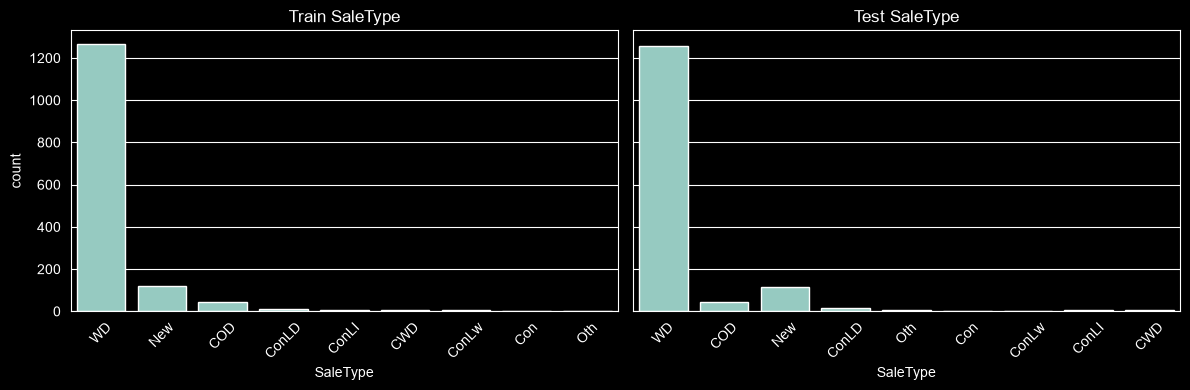

In [1514]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='SaleType', ax=axes[0])
axes[0].set_title('Train SaleType')

sns.countplot(data=df_test, x='SaleType', ax=axes[1])
axes[1].set_title('Test SaleType')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [1515]:
mode_by_year = df.groupby('YrSold')['SaleType'].agg(lambda x: x.mode()[0])
df_test['SaleType'] = df_test['SaleType'].fillna(df_test['YrSold'].map(mode_by_year))

SaleCondition

In [1512]:
print(df['SaleCondition'].isna().sum())
print(df_test['SaleCondition'].isna().sum())

0
0


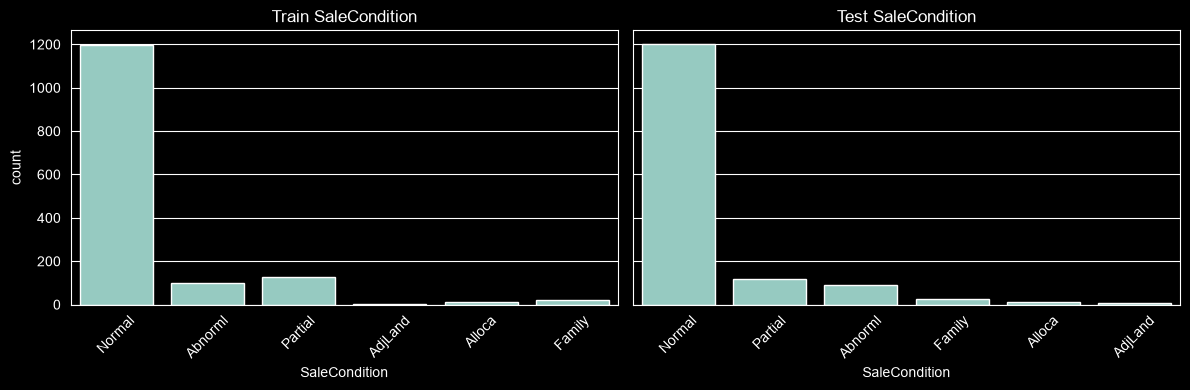

In [1513]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='SaleCondition', ax=axes[0])
axes[0].set_title('Train SaleCondition')

sns.countplot(data=df_test, x='SaleCondition', ax=axes[1])
axes[1].set_title('Test SaleCondition')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


In [1517]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Alley',
       'LotShape', 'LandContour', 'LotConfig', 'LandSlope', 'Neighborhood',
       'BldgType', 'OverallQual', 'OverallCond', 'RoofStyle', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond',
       'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
       'BsmtFinType2', 'TotalBsmtSF', 'HeatingQC', 'CentralAir', '1stFlrSF',
       '2ndFlrSF', 'GrLivArea', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'Fence',
       'YrSold', 'SaleType', 'SaleCondition', 'SalePrice', 'Is_Regular_Lot',
       'Is_Level_Land', 'RailRoad', 'NearStreet', 'NearPark',
       'HouseStyle_Group', 'House_Age', 'Remod_Age', 'Is_Remodeled',
       'Age_At_Remod', 

In [1451]:
# df_encoded = pd.get_dummies(df, columns=['MSSubClass'], prefix='MSSubClass', drop_first=True)
# from sklearn.preprocessing import OneHotEncoder
#
# ohe = OneHotEncoder(drop='first', sparse_output=False, dtype=int)
# encoded_array = ohe.fit_transform(df[['MSZoning']])
# encoded_df = pd.DataFrame(
#     encoded_array,
#     columns=ohe.get_feature_names_out(['MSZoning']),
#     index=df.index
# )
#
# df_encoded = df.drop(columns=['MSZoning']).join(encoded_df)